In [1]:
# ============================================================
# O2 — CONFIGURATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

O2_ROOT = Path("navic_o2")

O2_DATA_DIR = O2_ROOT / "data"
O2_RESULT_DIR = O2_ROOT / "results"
O2_MODEL_DIR = O2_ROOT / "models"

O2_DATA_DIR.mkdir(parents=True, exist_ok=True)
O2_RESULT_DIR.mkdir(parents=True, exist_ok=True)
O2_MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("O2 directories ready.")
print("Root:", O2_ROOT.resolve())

O2 directories ready.
Root: D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o2


In [2]:
# ============================================================
# O2 — LOAD O1 DATASET
# ============================================================

O1_DATA_PATH = Path(
    "navic_o1/data/processed/all_raw_cleaned.parquet"
)

df_o2 = pd.read_parquet(
    O1_DATA_PATH
)

df_o2["time"] = pd.to_datetime(
    df_o2["time"]
)

df_o2 = df_o2.sort_values(
    ["station", "sv", "time"]
).reset_index(drop=True)

print("=" * 70)
print("O2 BASE DATASET")
print("=" * 70)

print("Rows:", f"{len(df_o2):,}")

print("\nColumns:")
print(df_o2.columns.tolist())

print("\nStations:")
print(df_o2["station"].value_counts())

print("\nRaw observables:")
for c in ["C5A", "L5A", "S5A"]:
    print(
        c,
        "→",
        "AVAILABLE" if c in df_o2.columns else "MISSING"
    )

O2 BASE DATASET
Rows: 6,698,777

Columns:
['time', 'station', 'sv', 'station_lat', 'station_lon', 'year', 'day_of_year', 'solar_local_time', 'C5A', 'L5A', 'S5A', 'cn0_mean', 'cn0_std', 'cn0_variation', 'phase_diff', 'phase_rate', 'phase_residual', 'phase_variability', 's4_l5', 'sigma_phi', 'sigma_phi_proxy', 'lag_1', 'lag_2', 'lag_5', 'lag_10', 'lag_20', 'diff_1', 'abs_diff_1', 'rate_1', 'roll_mean_5', 'roll_std_5', 'roll_min_5', 'roll_max_5', 'roll_mean_10', 'roll_std_10', 'roll_min_10', 'roll_max_10', 'roll_mean_20', 'roll_std_20', 'roll_min_20', 'roll_max_20', 'epb_mild', 'epb_strong', 'condition', 'target_10min']

Stations:
station
IISC00IND    3756478
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Raw observables:
C5A → AVAILABLE
L5A → AVAILABLE
S5A → AVAILABLE


In [3]:
# ============================================================
# O2 — CHECK DOPPLER OBSERVABLE
# ============================================================

if "D5A" in df_o2.columns:

    print("✓ D5A already exists in O1 dataset.")

    HAS_REAL_DOPPLER = True

else:

    print("✗ D5A is NOT present in the O1 dataset.")

    HAS_REAL_DOPPLER = False

print(
    "\nReal Doppler available:",
    HAS_REAL_DOPPLER
)

✗ D5A is NOT present in the O1 dataset.

Real Doppler available: False


In [4]:
# ============================================================
# O2 — FIND RAW RINEX FILES AND CHECK DOPPLER
# Self-contained version
# ============================================================

from pathlib import Path
import georinex as gr
import numpy as np

# ------------------------------------------------------------
# Use the SAME raw-data location as the final O1 notebook
# ------------------------------------------------------------

PROJECT_ROOT = Path("navic_o1")

RAW_DIR = (
    PROJECT_ROOT /
    "data" /
    "raw"
)

print("Raw RINEX directory:")
print(RAW_DIR.resolve())

# ------------------------------------------------------------
# Find RINEX files
# ------------------------------------------------------------

raw_files_o2 = []

for path in RAW_DIR.rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()

    if (
        name.endswith(".rnx")
        or name.endswith(".crx")
        or name.endswith(".obs")
        or name.endswith(".rnx.gz")
        or name.endswith(".crx.gz")
        or name.endswith(".obs.gz")
    ):

        raw_files_o2.append(path)


raw_files_o2 = sorted(
    raw_files_o2
)

print(
    f"\nFound {len(raw_files_o2):,} raw RINEX files."
)

print("\nFirst 10 files:")

for f in raw_files_o2[:10]:
    print(f)

Raw RINEX directory:
D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o1\data\raw

Found 908 raw RINEX files.

First 10 files:
navic_o1\data\raw\IISC\2022\060\IISC00IND_R_20220600000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\060\IISC00IND_R_20220600000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\061\IISC00IND_R_20220610000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\061\IISC00IND_R_20220610000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\062\IISC00IND_R_20220620000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\062\IISC00IND_R_20220620000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\063\IISC00IND_R_20220630000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\063\IISC00IND_R_20220630000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\064\IISC00IND_R_20220640000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\064\IISC00IND_R_20220640000_01D_30S_MO.rnx


In [5]:
# ============================================================
# O2 — CHECK FOR NAVIC DOPPLER OBSERVABLE
# ============================================================

doppler_files_found = []

files_to_check = raw_files_o2[
    :min(50, len(raw_files_o2))
]

print(
    f"Checking {len(files_to_check)} files for "
    "NavIC Doppler observables...\n"
)

for i, rnx_path in enumerate(files_to_check):

    try:

        obs = gr.load(
            str(rnx_path),
            use="I"
        )

        available = [
            str(v)
            for v in obs.data_vars
        ]

        doppler_vars = [
            v
            for v in available
            if v.upper().startswith("D")
        ]

        if doppler_vars:

            doppler_files_found.append(
                (
                    rnx_path,
                    doppler_vars
                )
            )

            print(
                f"[FOUND] {rnx_path.name}"
            )

            print(
                "        Doppler:",
                doppler_vars
            )

    except Exception as e:

        print(
            f"[SKIP] {rnx_path.name}: {e}"
        )


print("\n" + "=" * 70)

print(
    "FILES WITH DOPPLER:",
    len(doppler_files_found)
)

print("=" * 70)

if doppler_files_found:

    print(
        "\nDoppler observables detected:"
    )

    all_doppler_vars = sorted(
        set(
            v
            for _, variables
            in doppler_files_found
            for v in variables
        )
    )

    print(
        all_doppler_vars
    )

else:

    print(
        "\nNo Doppler observables were found "
        "in the files checked."
    )

Checking 50 files for NavIC Doppler observables...


FILES WITH DOPPLER: 0

No Doppler observables were found in the files checked.


In [6]:
# ============================================================
# O2 — DOPPLER / DOPPLER-PROXY CONSTRUCTION
# ============================================================

# The checked NavIC RINEX files did not contain measured D5A in the
# current dataset. Therefore Doppler-related features use an L5A
# carrier-phase-derived proxy. If measured D5A is available in a
# future dataset, it is used directly and the proxy is not substituted.

if "D5A" in df_o2.columns:

    df_o2["doppler_proxy_hz"] = df_o2["D5A"]
    df_o2["doppler_source"] = "measured_D5A"
    HAS_REAL_DOPPLER = True

else:

    df_o2["carrier_phase_diff_o2"] = (
        df_o2.groupby(["station", "sv"])["L5A"].diff()
    )

    df_o2["carrier_phase_rate_o2"] = (
        df_o2["carrier_phase_diff_o2"] / 30.0
    )

    df_o2["doppler_proxy_hz"] = (
        -df_o2["carrier_phase_rate_o2"]
    )

    df_o2["doppler_source"] = (
        "L5A_carrier_phase_derived"
    )

    HAS_REAL_DOPPLER = False

print(
    "Doppler source:",
    "Measured D5A" if HAS_REAL_DOPPLER
    else "L5A carrier-phase-derived proxy"
)

Doppler source: L5A carrier-phase-derived proxy


In [7]:
# ============================================================
# O2 — BASE OBSERVATION DATASET
# ============================================================

O2_RAW_COLS = [
    "time",
    "station",
    "sv",

    "station_lat",
    "station_lon",
    "solar_local_time",
    "day_of_year",

    "C5A",
    "L5A",
    "S5A",

    "doppler_proxy_hz"
]

O2_RAW_COLS = [
    c for c in O2_RAW_COLS
    if c in df_o2.columns
]

o2_base = df_o2[
    O2_RAW_COLS
].copy()

o2_base = o2_base.sort_values(
    ["station", "sv", "time"]
)

o2_base = o2_base.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "O2 base shape:",
    o2_base.shape
)

print(
    "\nMissing percentage:"
)

print(
    o2_base.isna()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
)

O2 base shape: (6698777, 11)

Missing percentage:
doppler_proxy_hz    0.795459
L5A                 0.578225
S5A                 0.512706
C5A                 0.512706
sv                  0.000000
time                0.000000
station             0.000000
day_of_year         0.000000
solar_local_time    0.000000
station_lon         0.000000
station_lat         0.000000
dtype: float64


In [8]:
# ============================================================
# O2 — FEATURE ENGINEERING
# ============================================================

L5_FREQUENCY_HZ = 1176.45e6

C_LIGHT = 299792458.0

L5_WAVELENGTH_M = (
    C_LIGHT /
    L5_FREQUENCY_HZ
)


def engineer_o2_features(g):

    g = g.sort_values(
        "time"
    ).copy()

    # --------------------------------------------------------
    # BASIC SIGNAL QUALITY
    # --------------------------------------------------------

    g["cn0"] = g["S5A"]

    g["cn0_diff"] = (
        g["S5A"].diff()
    )

    g["cn0_rate"] = (
        g["cn0_diff"] /
        30.0
    )

    g["cn0_std_10"] = (
        g["S5A"]
        .rolling(10, min_periods=3)
        .std()
    )

    g["cn0_mean_10"] = (
        g["S5A"]
        .rolling(10, min_periods=3)
        .mean()
    )

    # --------------------------------------------------------
    # PSEUDORANGE
    # --------------------------------------------------------

    g["pseudorange"] = g["C5A"]

    g["pseudorange_diff"] = (
        g["C5A"].diff()
    )

    g["pseudorange_rate"] = (
        g["pseudorange_diff"] /
        30.0
    )

    g["pseudorange_accel"] = (
        g["pseudorange_rate"].diff() /
        30.0
    )

    g["pseudorange_std_10"] = (
        g["C5A"]
        .rolling(10, min_periods=3)
        .std()
    )

    # --------------------------------------------------------
    # CARRIER PHASE
    # --------------------------------------------------------

    g["carrier_phase"] = g["L5A"]

    g["carrier_phase_diff"] = (
        g["L5A"].diff()
    )

    g["carrier_phase_rate"] = (
        g["carrier_phase_diff"] /
        30.0
    )

    g["carrier_phase_accel"] = (
        g["carrier_phase_rate"].diff() /
        30.0
    )

    g["carrier_phase_std_10"] = (
        g["L5A"]
        .rolling(10, min_periods=3)
        .std()
    )

    # --------------------------------------------------------
    # PHASE JUMP
    # --------------------------------------------------------

    phase_step = (
        g["carrier_phase_diff"]
    )

    phase_step_median = (
        phase_step
        .rolling(10, min_periods=3)
        .median()
    )

    phase_step_std = (
        phase_step
        .rolling(10, min_periods=3)
        .std()
    )

    g["phase_jump_score"] = (
        (
            phase_step -
            phase_step_median
        ).abs()
        /
        (phase_step_std + 1e-6)
    )

    # --------------------------------------------------------
    # DOPPLER
    # --------------------------------------------------------

    g["doppler"] = (
        g["doppler_proxy_hz"]
    )

    g["doppler_diff"] = (
        g["doppler"].diff()
    )

    g["doppler_rate"] = (
        g["doppler_diff"] /
        30.0
    )

    g["doppler_accel"] = (
        g["doppler_rate"].diff() /
        30.0
    )

    g["doppler_std_10"] = (
        g["doppler"]
        .rolling(10, min_periods=3)
        .std()
    )

    g["doppler_jump_score"] = (
        (
            g["doppler_diff"] -
            g["doppler_diff"]
            .rolling(10, min_periods=3)
            .median()
        ).abs()
        /
        (
            g["doppler_diff"]
            .rolling(10, min_periods=3)
            .std()
            + 1e-6
        )
    )

    # --------------------------------------------------------
    # CODE-MINUS-CARRIER
    # --------------------------------------------------------

    # Carrier phase cycles → metres
    g["carrier_phase_m"] = (
        g["L5A"] *
        L5_WAVELENGTH_M
    )

    g["cmc"] = (
        g["C5A"] -
        g["carrier_phase_m"]
    )

    g["cmc_mean_10"] = (
        g["cmc"]
        .rolling(10, min_periods=3)
        .mean()
    )

    g["cmc_residual"] = (
        g["cmc"] -
        g["cmc_mean_10"]
    )

    g["cmc_std_10"] = (
        g["cmc"]
        .rolling(10, min_periods=3)
        .std()
    )

    # --------------------------------------------------------
    # PSEUDORANGE RATE vs CARRIER RATE
    # --------------------------------------------------------

    g["phase_range_rate_mps"] = (
        g["carrier_phase_rate"] *
        L5_WAVELENGTH_M
    )

    g["code_carrier_rate_residual"] = (
        g["pseudorange_rate"] -
        g["phase_range_rate_mps"]
    )

    # --------------------------------------------------------
    # DOPPLER / PHASE CONSISTENCY
    # --------------------------------------------------------

    # Determine sign convention from correlation
    valid = (
        g["doppler"].notna() &
        g["carrier_phase_rate"].notna()
    )

    if valid.sum() > 10:

        corr_positive = (
            g.loc[
                valid,
                "doppler"
            ].corr(
                g.loc[
                    valid,
                    "carrier_phase_rate"
                ]
            )
        )

        corr_negative = (
            g.loc[
                valid,
                "doppler"
            ].corr(
                -g.loc[
                    valid,
                    "carrier_phase_rate"
                ]
            )
        )

        if corr_negative >= corr_positive:
            expected_doppler = (
                -g["carrier_phase_rate"]
            )
        else:
            expected_doppler = (
                g["carrier_phase_rate"]
            )

    else:

        expected_doppler = (
            -g["carrier_phase_rate"]
        )

    g["doppler_phase_residual"] = (
        g["doppler"] -
        expected_doppler
    )

    # --------------------------------------------------------
    # TEMPORAL WINDOW FEATURES
    # --------------------------------------------------------

    for w in [5, 10, 20]:

        g[f"pr_rate_std_{w}"] = (
            g["pseudorange_rate"]
            .rolling(w, min_periods=3)
            .std()
        )

        g[f"doppler_rate_std_{w}"] = (
            g["doppler_rate"]
            .rolling(w, min_periods=3)
            .std()
        )

        g[f"cn0_std_{w}"] = (
            g["cn0"]
            .rolling(w, min_periods=3)
            .std()
        )

        g[f"cmc_std_{w}"] = (
            g["cmc_residual"]
            .rolling(w, min_periods=3)
            .std()
        )

    return g

In [9]:
# ============================================================
# APPLY O2 FEATURES
# ============================================================

o2_features = (
    o2_base
    .groupby(
        ["station", "sv"],
        group_keys=False
    )
    .apply(
        engineer_o2_features
    )
    .reset_index(drop=True)
)

print(
    "O2 feature dataset:",
    o2_features.shape
)

print("\nFeatures:")
print(
    o2_features.columns.tolist()
)

O2 feature dataset: (6698777, 51)

Features:
['time', 'station', 'sv', 'station_lat', 'station_lon', 'solar_local_time', 'day_of_year', 'C5A', 'L5A', 'S5A', 'doppler_proxy_hz', 'cn0', 'cn0_diff', 'cn0_rate', 'cn0_std_10', 'cn0_mean_10', 'pseudorange', 'pseudorange_diff', 'pseudorange_rate', 'pseudorange_accel', 'pseudorange_std_10', 'carrier_phase', 'carrier_phase_diff', 'carrier_phase_rate', 'carrier_phase_accel', 'carrier_phase_std_10', 'phase_jump_score', 'doppler', 'doppler_diff', 'doppler_rate', 'doppler_accel', 'doppler_std_10', 'doppler_jump_score', 'carrier_phase_m', 'cmc', 'cmc_mean_10', 'cmc_residual', 'cmc_std_10', 'phase_range_rate_mps', 'code_carrier_rate_residual', 'doppler_phase_residual', 'pr_rate_std_5', 'doppler_rate_std_5', 'cn0_std_5', 'cmc_std_5', 'pr_rate_std_10', 'doppler_rate_std_10', 'pr_rate_std_20', 'doppler_rate_std_20', 'cn0_std_20', 'cmc_std_20']


In [10]:
O2_FEATURE_PATH = (
    O2_DATA_DIR /
    "o2_clean_features.parquet"
)

o2_features.to_parquet(
    O2_FEATURE_PATH,
    index=False
)

print(
    "Saved:",
    O2_FEATURE_PATH
)

Saved: navic_o2\data\o2_clean_features.parquet


In [11]:
# ============================================================
# O2 — CHRONOLOGICAL SPLIT
# ============================================================

o2_features["split"] = "unknown"

for key, g in o2_features.groupby(
    ["station", "sv"],
    sort=False
):

    g = g.sort_values("time")

    n = len(g)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )

    idx = g.index

    o2_features.loc[
        idx[:train_end],
        "split"
    ] = "train"

    o2_features.loc[
        idx[train_end:val_end],
        "split"
    ] = "val"

    o2_features.loc[
        idx[val_end:],
        "split"
    ] = "test"


print(
    o2_features["split"]
    .value_counts()
)

split
train    4689135
test     1004824
val      1004818
Name: count, dtype: int64


In [12]:
# ============================================================
# O2 — MULTIPATH INJECTION
# ============================================================

def inject_multipath(
    g,
    rng,
    attack_fraction=0.35
):

    g = g.copy()

    n = len(g)

    g["attack_label"] = 0

    if n < 50:
        return g

    target_points = int(
        n * attack_fraction
    )

    modified = 0

    while modified < target_points:

        start = rng.integers(
            20,
            max(21, n - 20)
        )

        length = int(
            rng.integers(20, 61)
        )

        end = min(
            start + length,
            n
        )

        L = end - start

        if L < 10:
            continue

        t = np.arange(L)

        envelope = (
            np.sin(
                np.pi *
                t /
                max(L - 1, 1)
            ) ** 2
        )

        frequency = rng.uniform(
            0.03,
            0.12
        )

        phase_offset = rng.uniform(
            0,
            2 * np.pi
        )

        oscillation = (
            envelope *
            np.sin(
                2 * np.pi *
                frequency *
                t +
                phase_offset
            )
        )

        # --------------------------------------------
        # Multipath perturbations
        # --------------------------------------------

        code_amp = rng.uniform(
            2.0,
            8.0
        )

        phase_amp = rng.uniform(
            0.03,
            0.20
        )

        cn0_amp = rng.uniform(
            1.0,
            4.0
        )

        phase_delta = (
            phase_amp *
            oscillation
        )

        doppler_delta = (
            -np.gradient(
                phase_delta,
                30.0
            )
        )

        g.loc[
            g.index[start:end],
            "C5A"
        ] += (
            code_amp *
            oscillation
        )

        g.loc[
            g.index[start:end],
            "L5A"
        ] += phase_delta

        g.loc[
            g.index[start:end],
            "S5A"
        ] += (
            -cn0_amp *
            np.abs(oscillation)
        )

        g.loc[
            g.index[start:end],
            "doppler_proxy_hz"
        ] += doppler_delta

        g.loc[
            g.index[start:end],
            "attack_label"
        ] = 1

        modified += L

    return g

In [13]:
# ============================================================
# O2 — SPOOFING INJECTION
# ============================================================

def inject_spoofing(
    g,
    rng,
    attack_fraction=0.35
):

    g = g.copy()

    n = len(g)

    g["attack_label"] = 0

    if n < 50:
        return g

    target_points = int(
        n * attack_fraction
    )

    modified = 0

    while modified < target_points:

        start = rng.integers(
            20,
            max(21, n - 20)
        )

        length = int(
            rng.integers(30, 81)
        )

        end = min(
            start + length,
            n
        )

        L = end - start

        if L < 10:
            continue

        t = np.arange(L)

        # --------------------------------------------
        # Gradual takeover / drag-off envelope
        # --------------------------------------------

        ramp = np.linspace(
            0,
            1,
            L
        )

        smooth_ramp = (
            3 * ramp**2 -
            2 * ramp**3
        )

        # --------------------------------------------
        # Attack parameters
        # --------------------------------------------

        code_bias = rng.uniform(
            5.0,
            30.0
        )

        phase_bias = rng.uniform(
            0.5,
            4.0
        )

        cn0_gain = rng.uniform(
            1.0,
            4.0
        )

        doppler_bias = rng.uniform(
            0.2,
            2.0
        )

        # --------------------------------------------
        # Pseudorange drag-off
        # --------------------------------------------

        code_delta = (
            code_bias *
            smooth_ramp
        )

        # --------------------------------------------
        # Carrier phase drag-off
        # --------------------------------------------

        phase_delta = (
            phase_bias *
            smooth_ramp
        )

        # Expected Doppler from phase
        expected_doppler_delta = (
            -np.gradient(
                phase_delta,
                30.0
            )
        )

        # Deliberate small Doppler inconsistency
        # to model receiver-observable attack signature.
        doppler_mismatch = (
            doppler_bias *
            smooth_ramp
        )

        doppler_delta = (
            expected_doppler_delta +
            doppler_mismatch
        )

        # --------------------------------------------
        # Signal power change
        # --------------------------------------------

        cn0_delta = (
            cn0_gain *
            smooth_ramp
        )

        # --------------------------------------------
        # Apply attack
        # --------------------------------------------

        g.loc[
            g.index[start:end],
            "C5A"
        ] += code_delta

        g.loc[
            g.index[start:end],
            "L5A"
        ] += phase_delta

        g.loc[
            g.index[start:end],
            "S5A"
        ] += cn0_delta

        g.loc[
            g.index[start:end],
            "doppler_proxy_hz"
        ] += doppler_delta

        g.loc[
            g.index[start:end],
            "attack_label"
        ] = 2

        modified += L

    return g

In [14]:
# ============================================================
# O2 — MULTI-CLASS SCENARIO GENERATION
# ============================================================

CLASS_MAP = {
    0: "Genuine",
    1: "Multipath",
    2: "Spoofing"
}

rng = np.random.default_rng(RANDOM_STATE)


def _attach_scenario_metadata(g, split_name, class_id):

    g = g.copy()
    class_name = CLASS_MAP[class_id]

    # scenario_id prevents feature-engineering windows from crossing
    # the genuine/multipath/spoofing scenario boundaries.
    g["scenario_id"] = (
        g["station"].astype(str) + "_" +
        g["sv"].astype(str) + "_" +
        split_name + "_" +
        class_name.lower()
    )

    g["class_name"] = class_name
    g["split"] = split_name
    return g


def generate_o2_split(source_df, split_name):

    parts = []

    source_split = source_df[
        source_df["split"] == split_name
    ].copy()

    for key, g in source_split.groupby(
        ["station", "sv"],
        sort=False
    ):

        g = g.sort_values("time").copy()

        genuine = g.copy()
        genuine["attack_label"] = 0
        parts.append(
            _attach_scenario_metadata(genuine, split_name, 0)
        )

        multipath = inject_multipath(g, rng)
        parts.append(
            _attach_scenario_metadata(multipath, split_name, 1)
        )

        spoofing = inject_spoofing(g, rng)
        parts.append(
            _attach_scenario_metadata(spoofing, split_name, 2)
        )

    result = pd.concat(parts, ignore_index=True)
    return result

In [15]:
# ============================================================
# GENERATE TRAIN / VAL / TEST SCENARIOS
# ============================================================

o2_train_raw = generate_o2_split(
    o2_features,
    "train"
)

o2_val_raw = generate_o2_split(
    o2_features,
    "val"
)

o2_test_raw = generate_o2_split(
    o2_features,
    "test"
)

print(
    "Train:",
    o2_train_raw.shape
)

print(
    "Validation:",
    o2_val_raw.shape
)

print(
    "Test:",
    o2_test_raw.shape
)

print("\nTrain classes:")
print(
    o2_train_raw["class_name"]
    .value_counts()
)

Train: (14067405, 55)
Validation: (3014454, 55)
Test: (3014472, 55)

Train classes:
class_name
Genuine      4689135
Multipath    4689135
Spoofing     4689135
Name: count, dtype: int64


In [16]:
# ============================================================
# RECOMPUTE FEATURES AFTER ATTACK INJECTION
# ============================================================

def rebuild_o2_features(scenario_df):

    raw_columns = [
        "time", "station", "sv",
        "station_lat", "station_lon",
        "solar_local_time", "day_of_year",
        "C5A", "L5A", "S5A", "doppler_proxy_hz",
        "attack_label", "class_name", "split", "scenario_id"
    ]

    raw_columns = [
        c for c in raw_columns
        if c in scenario_df.columns
    ]

    base = scenario_df[raw_columns].copy()

    # IMPORTANT: engineer rolling/rate features independently inside
    # each scenario. This prevents leakage across the three duplicated
    # scenario realizations of the same station/satellite time series.
    result = (
        base
        .groupby("scenario_id", group_keys=False, sort=False)
        .apply(engineer_o2_features)
        .reset_index(drop=True)
    )

    return result


o2_train = rebuild_o2_features(o2_train_raw)
o2_val = rebuild_o2_features(o2_val_raw)
o2_test = rebuild_o2_features(o2_test_raw)

print("Train:", o2_train.shape)
print("Validation:", o2_val.shape)
print("Test:", o2_test.shape)
print("Scenario IDs — train:", o2_train["scenario_id"].nunique())

Train: (14067405, 55)
Validation: (3014454, 55)
Test: (3014472, 55)
Scenario IDs — train: 78


In [17]:
# ============================================================
# O2 — FINAL FEATURE LIST
# ============================================================

O2_FEATURES = [

    # --------------------------------------------
    # Signal quality
    # --------------------------------------------

    "cn0",
    "cn0_diff",
    "cn0_rate",
    "cn0_std_10",
    "cn0_mean_10",

    # --------------------------------------------
    # Pseudorange
    # --------------------------------------------

    "pseudorange",
    "pseudorange_diff",
    "pseudorange_rate",
    "pseudorange_accel",
    "pseudorange_std_10",

    # --------------------------------------------
    # Carrier phase
    # --------------------------------------------

    "carrier_phase",
    "carrier_phase_diff",
    "carrier_phase_rate",
    "carrier_phase_accel",
    "carrier_phase_std_10",
    "phase_jump_score",

    # --------------------------------------------
    # Doppler
    # --------------------------------------------

    "doppler",
    "doppler_diff",
    "doppler_rate",
    "doppler_accel",
    "doppler_std_10",
    "doppler_jump_score",

    # --------------------------------------------
    # Code-carrier consistency
    # --------------------------------------------

    "cmc_residual",
    "cmc_std_10",

    "phase_range_rate_mps",

    "code_carrier_rate_residual",

    # --------------------------------------------
    # Doppler-phase consistency
    # --------------------------------------------

    "doppler_phase_residual",

    # --------------------------------------------
    # Temporal features
    # --------------------------------------------

    "pr_rate_std_5",
    "pr_rate_std_10",
    "pr_rate_std_20",

    "doppler_rate_std_5",
    "doppler_rate_std_10",
    "doppler_rate_std_20",

    "cn0_std_5",
    "cn0_std_10",
    "cn0_std_20",

    "cmc_std_5",
    "cmc_std_10",
    "cmc_std_20",
]


O2_FEATURES = [
    c for c in O2_FEATURES
    if c in o2_train.columns
]

print(
    "Number of O2 features:",
    len(O2_FEATURES)
)

for f in O2_FEATURES:
    print("✓", f)

Number of O2 features: 39
✓ cn0
✓ cn0_diff
✓ cn0_rate
✓ cn0_std_10
✓ cn0_mean_10
✓ pseudorange
✓ pseudorange_diff
✓ pseudorange_rate
✓ pseudorange_accel
✓ pseudorange_std_10
✓ carrier_phase
✓ carrier_phase_diff
✓ carrier_phase_rate
✓ carrier_phase_accel
✓ carrier_phase_std_10
✓ phase_jump_score
✓ doppler
✓ doppler_diff
✓ doppler_rate
✓ doppler_accel
✓ doppler_std_10
✓ doppler_jump_score
✓ cmc_residual
✓ cmc_std_10
✓ phase_range_rate_mps
✓ code_carrier_rate_residual
✓ doppler_phase_residual
✓ pr_rate_std_5
✓ pr_rate_std_10
✓ pr_rate_std_20
✓ doppler_rate_std_5
✓ doppler_rate_std_10
✓ doppler_rate_std_20
✓ cn0_std_5
✓ cn0_std_10
✓ cn0_std_20
✓ cmc_std_5
✓ cmc_std_10
✓ cmc_std_20


In [18]:
# ============================================================
# O2 — BALANCED DATASET SAMPLING
# ============================================================

MAX_TRAIN_PER_CLASS = 250_000
MAX_VAL_PER_CLASS = 75_000
MAX_TEST_PER_CLASS = 75_000


def balance_dataset(
    data,
    max_per_class,
    random_state=42
):

    parts = []

    for label in sorted(
        data["attack_label"].unique()
    ):

        g = data[
            data["attack_label"] == label
        ].copy()

        if len(g) > max_per_class:

            g = g.sample(
                n=max_per_class,
                random_state=random_state
            )

        parts.append(g)

    result = pd.concat(
        parts,
        ignore_index=True
    )

    return result.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)


o2_train_model = balance_dataset(
    o2_train,
    MAX_TRAIN_PER_CLASS
)

o2_val_model = balance_dataset(
    o2_val,
    MAX_VAL_PER_CLASS
)

o2_test_model = balance_dataset(
    o2_test,
    MAX_TEST_PER_CLASS
)

print("TRAIN")
print(
    o2_train_model["class_name"]
    .value_counts()
)

print("\nVALIDATION")
print(
    o2_val_model["class_name"]
    .value_counts()
)

print("\nTEST")
print(
    o2_test_model["class_name"]
    .value_counts()
)

TRAIN
class_name
Multipath    323308
Spoofing     322880
Genuine      103812
Name: count, dtype: int64

VALIDATION
class_name
Spoofing     96997
Multipath    96824
Genuine      31179
Name: count, dtype: int64

TEST
class_name
Multipath    96920
Spoofing     96911
Genuine      31169
Name: count, dtype: int64


In [19]:
# ============================================================
# O2 — TRAIN-ONLY IMPUTATION
# ============================================================

O2_FEATURES = list(dict.fromkeys(O2_FEATURES))

missing_features = [
    c for c in O2_FEATURES
    if c not in o2_train_model.columns
]

if missing_features:
    raise ValueError(
        f"Missing O2 features in training data: {missing_features}"
    )

for df_model in [
    o2_train_model,
    o2_val_model,
    o2_test_model
]:
    df_model.loc[:, O2_FEATURES] = (
        df_model.loc[:, O2_FEATURES]
        .replace([np.inf, -np.inf], np.nan)
    )

train_medians = (
    o2_train_model[O2_FEATURES]
    .median(numeric_only=True)
)

for df_model in [
    o2_train_model,
    o2_val_model,
    o2_test_model
]:
    df_model.loc[:, O2_FEATURES] = (
        df_model.loc[:, O2_FEATURES]
        .fillna(train_medians)
    )

remaining_nan = {
    split: int(
        df_model[O2_FEATURES].isna().sum().sum()
    )
    for split, df_model in [
        ("train", o2_train_model),
        ("validation", o2_val_model),
        ("test", o2_test_model)
    ]
}

print("Remaining NaN values:", remaining_nan)

Remaining NaN values: {'train': 0, 'validation': 0, 'test': 0}


In [20]:
# ============================================================
# O2 — MODEL MATRICES
# ============================================================

X_train = (
    o2_train_model[
        O2_FEATURES
    ]
    .astype(np.float32)
)

y_train = (
    o2_train_model[
        "attack_label"
    ]
    .astype(int)
)

X_val = (
    o2_val_model[
        O2_FEATURES
    ]
    .astype(np.float32)
)

y_val = (
    o2_val_model[
        "attack_label"
    ]
    .astype(int)
)

X_test = (
    o2_test_model[
        O2_FEATURES
    ]
    .astype(np.float32)
)

y_test = (
    o2_test_model[
        "attack_label"
    ]
    .astype(int)
)

print(
    "X_train:",
    X_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "X_test:",
    X_test.shape
)

X_train: (750000, 37)
X_val: (225000, 37)
X_test: (225000, 37)


In [21]:
print("Train columns:")
print(o2_train_model.columns.tolist())

print("\nColumns containing 'class', 'label', or 'threat':")
print([
    c for c in o2_train_model.columns
    if any(x in c.lower() for x in ["class", "label", "threat"])
])

Train columns:
['time', 'station', 'sv', 'station_lat', 'station_lon', 'solar_local_time', 'day_of_year', 'C5A', 'L5A', 'S5A', 'doppler_proxy_hz', 'attack_label', 'class_name', 'split', 'scenario_id', 'cn0', 'cn0_diff', 'cn0_rate', 'cn0_std_10', 'cn0_mean_10', 'pseudorange', 'pseudorange_diff', 'pseudorange_rate', 'pseudorange_accel', 'pseudorange_std_10', 'carrier_phase', 'carrier_phase_diff', 'carrier_phase_rate', 'carrier_phase_accel', 'carrier_phase_std_10', 'phase_jump_score', 'doppler', 'doppler_diff', 'doppler_rate', 'doppler_accel', 'doppler_std_10', 'doppler_jump_score', 'carrier_phase_m', 'cmc', 'cmc_mean_10', 'cmc_residual', 'cmc_std_10', 'phase_range_rate_mps', 'code_carrier_rate_residual', 'doppler_phase_residual', 'pr_rate_std_5', 'doppler_rate_std_5', 'cn0_std_5', 'cmc_std_5', 'pr_rate_std_10', 'doppler_rate_std_10', 'pr_rate_std_20', 'doppler_rate_std_20', 'cn0_std_20', 'cmc_std_20']

Columns containing 'class', 'label', or 'threat':
['attack_label', 'class_name']


In [22]:
print("\nShape:", o2_train_model.shape)

for c in o2_train_model.columns:
    if c not in O2_FEATURES:
        print(f"Possible target/metadata column: {c}")


Shape: (750000, 55)
Possible target/metadata column: time
Possible target/metadata column: station
Possible target/metadata column: sv
Possible target/metadata column: station_lat
Possible target/metadata column: station_lon
Possible target/metadata column: solar_local_time
Possible target/metadata column: day_of_year
Possible target/metadata column: C5A
Possible target/metadata column: L5A
Possible target/metadata column: S5A
Possible target/metadata column: doppler_proxy_hz
Possible target/metadata column: attack_label
Possible target/metadata column: class_name
Possible target/metadata column: split
Possible target/metadata column: scenario_id
Possible target/metadata column: carrier_phase_m
Possible target/metadata column: cmc
Possible target/metadata column: cmc_mean_10


In [60]:
%pip install numpy pandas scipy scikit-learn matplotlib seaborn joblib xgboost lightgbm catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
# ============================================================
# O2 — MODEL / TRAINING CONFIGURATION
# ============================================================

import time
import os
import joblib

CLASS_NAMES = ["Genuine", "Multipath", "Spoofing"]
N_CLASSES = 3

# Neural models are capped independently to keep the benchmark practical
# on CPU-only machines. Tree models use the full balanced training set.
DL_MAX_TRAIN_ROWS = 300_000
MLP_HIDDEN = (128, 64)
MLP_MAX_ITER = 40

TABM_MAX_TRAIN_ROWS = 300_000
TABM_K = 8
TABM_EPOCHS = 20
TABM_BATCH_SIZE = 4096
TABM_LR = 0.002
TABM_WEIGHT_DECAY = 3e-4
TABM_D_BLOCK = 256
TABM_N_BLOCKS = 2

RUN_TABM = True

print("Train rows:", len(X_train))
print("DL cap:", DL_MAX_TRAIN_ROWS)
print("TabM enabled:", RUN_TABM)

Train rows: 750000
DL cap: 300000
TabM enabled: True


In [24]:
# ============================================================
# O2 — STRATIFIED SUBSET FOR NEURAL MODELS
# ============================================================

from sklearn.model_selection import train_test_split


def stratified_cap(X, y, max_rows, random_state=42):
    if len(X) <= max_rows:
        return X.copy(), y.copy()

    idx = np.arange(len(y))
    keep, _ = train_test_split(
        idx,
        train_size=max_rows,
        stratify=y,
        random_state=random_state
    )

    return X.iloc[keep].reset_index(drop=True), y.iloc[keep].reset_index(drop=True)


X_train_dl, y_train_dl = stratified_cap(
    X_train,
    y_train,
    DL_MAX_TRAIN_ROWS,
    RANDOM_STATE
)

print("Neural training subset:", X_train_dl.shape)
print(y_train_dl.value_counts().sort_index())

Neural training subset: (300000, 37)
attack_label
0    100000
1    100000
2    100000
Name: count, dtype: int64


In [25]:
# ============================================================
# O2 — LOGISTIC REGRESSION
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=500,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Training Logistic Regression...")
t0 = time.perf_counter()
logreg_model.fit(X_train, y_train)
training_times = {"Logistic Regression": time.perf_counter() - t0}
print(f"Completed in {training_times['Logistic Regression']:.2f} s")

Training Logistic Regression...
Completed in 16.90 s


In [26]:
# ============================================================
# O2 — RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    max_features="sqrt"
)

print("Training Random Forest...")
t0 = time.perf_counter()
rf_model.fit(X_train, y_train)
training_times["Random Forest"] = time.perf_counter() - t0
print(f"Completed in {training_times['Random Forest']:.2f} s")

Training Random Forest...
Completed in 396.36 s


In [27]:
# ============================================================
# O2 — XGBOOST MULTI-CLASS
# ============================================================

import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    reg_alpha=0.0,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Training XGBoost...")
t0 = time.perf_counter()
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)
training_times["XGBoost"] = time.perf_counter() - t0
print(f"Completed in {training_times['XGBoost']:.2f} s")

Training XGBoost...
Completed in 139.30 s


In [28]:
# ============================================================
# O2 — LIGHTGBM MULTI-CLASS
# ============================================================

try:
    import lightgbm as lgb

    lgb_model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=3,
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        max_depth=-1,
        min_child_samples=40,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )

    print("Training LightGBM...")
    t0 = time.perf_counter()
    lgb_model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    training_times["LightGBM"] = time.perf_counter() - t0
    print(f"Completed in {training_times['LightGBM']:.2f} s")

except Exception as e:
    lgb_model = None
    print("LightGBM skipped:", e)

Training LightGBM...
Completed in 52.61 s


In [29]:
# ============================================================
# O2 — CATBOOST MULTI-CLASS
# ============================================================

try:
    from catboost import CatBoostClassifier

    cat_model = CatBoostClassifier(
        loss_function="MultiClass",
        iterations=500,
        depth=8,
        learning_rate=0.05,
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=-1,
        verbose=False,
        allow_writing_files=False
    )

    print("Training CatBoost...")
    t0 = time.perf_counter()
    cat_model.fit(
        X_train,
        y_train,
        eval_set=(X_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )
    training_times["CatBoost"] = time.perf_counter() - t0
    print(f"Completed in {training_times['CatBoost']:.2f} s")

except Exception as e:
    cat_model = None
    print("CatBoost skipped:", e)

Training CatBoost...
Completed in 444.68 s


In [30]:
# ============================================================
# O2 — MLP BASELINE
# ============================================================

from sklearn.neural_network import MLPClassifier

mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=MLP_HIDDEN,
        activation="relu",
        solver="adam",
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=MLP_MAX_ITER,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5,
        random_state=RANDOM_STATE,
        verbose=False
    ))
])

print("Training MLP on capped stratified subset...")
t0 = time.perf_counter()
mlp_model.fit(X_train_dl, y_train_dl)
training_times["MLP"] = time.perf_counter() - t0
print(f"Completed in {training_times['MLP']:.2f} s")

Training MLP on capped stratified subset...
Completed in 42.34 s


In [31]:
# ============================================================
# O2 — OPTIONAL PACKAGE SETUP
# ============================================================
# If any package is missing in your environment, run the appropriate
# installation command below and restart the kernel if requested.
#
# %pip install lightgbm catboost
# %pip install tabm rtdl_num_embeddings

print("Required classical packages: lightgbm, catboost")
print("Optional modern DL package: tabm, rtdl_num_embeddings")


Required classical packages: lightgbm, catboost
Optional modern DL package: tabm, rtdl_num_embeddings


In [59]:
%pip install torch tabm rtdl_num_embeddings aeon

   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   -------------------------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\VARADHARAJAN K\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "c:\Users\VARADHARAJAN K\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\VARADHARAJAN K\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\VARADHARAJAN K\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(am

In [32]:
# ============================================================
# O2 — TABM (OPTIONAL MODERN TABULAR DL MODEL)
# ============================================================

TABM_AVAILABLE = False
TABM_ERROR = None

try:
    import torch
    from tabm import TabM
    TABM_AVAILABLE = True
    print("TabM package available.")
    print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
except Exception as e:
    TABM_ERROR = str(e)
    print("TabM is not available in this environment.")
    print("Install with: pip install tabm rtdl_num_embeddings")
    print("Reason:", e)


if RUN_TABM and TABM_AVAILABLE:

    class TabMClassifier:
        """Small sklearn-like wrapper around the official TabM package."""

        def __init__(
            self,
            n_features,
            n_classes=3,
            k=8,
            d_block=256,
            n_blocks=2,
            dropout=0.1,
            epochs=20,
            batch_size=4096,
            lr=0.002,
            weight_decay=3e-4,
            random_state=42,
        ):
            self.n_features = n_features
            self.n_classes = n_classes
            self.k = k
            self.epochs = epochs
            self.batch_size = batch_size
            self.lr = lr
            self.weight_decay = weight_decay
            self.random_state = random_state
            self.device = torch.device(
                "cuda" if torch.cuda.is_available() else "cpu"
            )

            torch.manual_seed(random_state)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(random_state)

            self.model = TabM.make(
                n_num_features=n_features,
                d_out=n_classes,
                k=k,
                n_blocks=n_blocks,
                d_block=d_block,
                dropout=dropout,
                arch_type="tabm"
            ).to(self.device)

        def fit(self, X, y, X_val=None, y_val=None):
            X_np = np.asarray(X, dtype=np.float32)
            y_np = np.asarray(y, dtype=np.int64)

            if X_val is not None:
                Xv_np = np.asarray(X_val, dtype=np.float32)
                yv_np = np.asarray(y_val, dtype=np.int64)
            else:
                Xv_np, yv_np = None, None

            # Standardization is important for neural tabular models.
            self.mean_ = X_np.mean(axis=0).astype(np.float32)
            self.std_ = X_np.std(axis=0).astype(np.float32)
            self.std_[self.std_ < 1e-8] = 1.0
            X_np = (X_np - self.mean_) / self.std_
            if Xv_np is not None:
                Xv_np = (Xv_np - self.mean_) / self.std_

            ds = torch.utils.data.TensorDataset(
                torch.from_numpy(X_np),
                torch.from_numpy(y_np)
            )
            loader = torch.utils.data.DataLoader(
                ds,
                batch_size=self.batch_size,
                shuffle=True,
                num_workers=0,
                pin_memory=torch.cuda.is_available()
            )

            optimizer = torch.optim.AdamW(
                self.model.parameters(),
                lr=self.lr,
                weight_decay=self.weight_decay
            )
            criterion = torch.nn.CrossEntropyLoss()

            best_state = None
            best_val = np.inf
            patience = 4
            stale = 0

            for epoch in range(self.epochs):
                self.model.train()
                running = 0.0
                count = 0

                for xb, yb in loader:
                    xb = xb.to(self.device, non_blocking=True)
                    yb = yb.to(self.device, non_blocking=True)

                    optimizer.zero_grad(set_to_none=True)
                    logits = self.model(xb)
                    # Official TabM returns [B, K, C].
                    loss = criterion(
                        logits.reshape(-1, self.n_classes),
                        yb[:, None].expand(-1, logits.shape[1]).reshape(-1)
                    )
                    loss.backward()
                    optimizer.step()

                    running += loss.item() * len(yb)
                    count += len(yb)

                train_loss = running / max(count, 1)

                if Xv_np is not None:
                    self.model.eval()
                    with torch.no_grad():
                        xv = torch.from_numpy(Xv_np).to(self.device)
                        logits = self.model(xv)
                        val_logits = logits.mean(dim=1)
                        yv = torch.from_numpy(yv_np).to(self.device)
                        val_loss = criterion(val_logits, yv).item()

                    if val_loss < best_val:
                        best_val = val_loss
                        best_state = {
                            k: v.detach().cpu().clone()
                            for k, v in self.model.state_dict().items()
                        }
                        stale = 0
                    else:
                        stale += 1
                        if stale >= patience:
                            print(f"Early stopping at epoch {epoch + 1}.")
                            break

                    print(
                        f"Epoch {epoch + 1:02d} | "
                        f"train loss={train_loss:.4f} | "
                        f"val loss={val_loss:.4f}"
                    )
                else:
                    print(
                        f"Epoch {epoch + 1:02d} | "
                        f"train loss={train_loss:.4f}"
                    )

            if best_state is not None:
                self.model.load_state_dict(best_state)
                self.model.to(self.device)

            return self

        def _scaled_tensor(self, X):
            X_np = np.asarray(X, dtype=np.float32)
            X_np = (X_np - self.mean_) / self.std_
            return torch.from_numpy(X_np)

        def predict_proba(self, X):
            self.model.eval()
            xb = self._scaled_tensor(X)
            outputs = []
            with torch.no_grad():
                for start in range(0, len(xb), self.batch_size):
                    batch = xb[start:start + self.batch_size].to(self.device)
                    logits = self.model(batch).mean(dim=1)
                    outputs.append(torch.softmax(logits, dim=1).cpu().numpy())
            return np.vstack(outputs)

        def predict(self, X):
            return np.argmax(self.predict_proba(X), axis=1)


    tabm_model = TabMClassifier(
        n_features=len(O2_FEATURES),
        n_classes=N_CLASSES,
        k=TABM_K,
        d_block=TABM_D_BLOCK,
        n_blocks=TABM_N_BLOCKS,
        epochs=TABM_EPOCHS,
        batch_size=TABM_BATCH_SIZE,
        lr=TABM_LR,
        weight_decay=TABM_WEIGHT_DECAY,
        random_state=RANDOM_STATE
    )

    print("Training TabM on capped stratified subset...")
    t0 = time.perf_counter()
    tabm_model.fit(
        X_train_dl,
        y_train_dl,
        X_val=X_val,
        y_val=y_val
    )
    training_times["TabM"] = time.perf_counter() - t0
    print(f"Completed in {training_times['TabM']:.2f} s")
else:
    tabm_model = None

TabM package available.
Device: cpu
Training TabM on capped stratified subset...
Epoch 01 | train loss=0.6581 | val loss=0.5288
Epoch 02 | train loss=0.5243 | val loss=0.4933
Epoch 03 | train loss=0.4918 | val loss=0.4734
Epoch 04 | train loss=0.4747 | val loss=0.4622
Epoch 05 | train loss=0.4624 | val loss=0.4540
Epoch 06 | train loss=0.4534 | val loss=0.4475
Epoch 07 | train loss=0.4442 | val loss=0.4374
Epoch 08 | train loss=0.4323 | val loss=0.4208
Epoch 09 | train loss=0.4236 | val loss=0.4176
Epoch 10 | train loss=0.4187 | val loss=0.4109
Epoch 11 | train loss=0.4140 | val loss=0.4101
Epoch 12 | train loss=0.4088 | val loss=0.4073
Epoch 13 | train loss=0.4082 | val loss=0.4115
Epoch 14 | train loss=0.4062 | val loss=0.4041
Epoch 15 | train loss=0.4072 | val loss=0.4000
Epoch 16 | train loss=0.4018 | val loss=0.3973
Epoch 17 | train loss=0.3977 | val loss=0.3972
Epoch 18 | train loss=0.3999 | val loss=0.3989
Epoch 19 | train loss=0.3956 | val loss=0.3962
Epoch 20 | train loss=0.39

In [33]:
# ============================================================
# O2 — UNIFIED MODEL REGISTRY
# ============================================================

models = {
    "Logistic Regression": logreg_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
}

if lgb_model is not None:
    models["LightGBM"] = lgb_model

if cat_model is not None:
    models["CatBoost"] = cat_model

models["MLP"] = mlp_model

if tabm_model is not None:
    models["TabM"] = tabm_model

print("Models included in benchmark:")
for name in models:
    print(" -", name)

Models included in benchmark:
 - Logistic Regression
 - Random Forest
 - XGBoost
 - LightGBM
 - CatBoost
 - MLP
 - TabM


In [34]:
# ============================================================
# O2 — UNIFIED EVALUATION FUNCTIONS
# ============================================================

from sklearn.preprocessing import label_binarize

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)


def evaluate_classifier(model, name, X, y):

    t0 = time.perf_counter()
    pred = model.predict(X)
    inference_seconds = time.perf_counter() - t0

    probability = None
    if hasattr(model, "predict_proba"):
        probability = model.predict_proba(X)

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y, pred),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "Macro Precision": precision_score(y, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y, pred, average="weighted", zero_division=0),
        "ROC-AUC": np.nan,
        "PR-AUC": np.nan,
        "Inference ms/sample": (inference_seconds / len(y)) * 1000,
        "Training seconds": training_times.get(name, np.nan),
    }

    if probability is not None:
        try:
            result["ROC-AUC"] = roc_auc_score(
                y, probability, multi_class="ovr", average="macro"
            )
            y_bin = label_binarize(y, classes=[0, 1, 2])
            result["PR-AUC"] = average_precision_score(
                y_bin, probability, average="macro"
            )
        except Exception:
            pass

    return result, pred, probability


validation_records = []
validation_cache = {}

for name, model in models.items():
    print(f"Evaluating {name} on balanced validation set...")
    result, pred, probability = evaluate_classifier(
        model, name, X_val, y_val
    )
    validation_records.append(result)
    validation_cache[name] = {
        "pred": pred,
        "probability": probability
    }

validation_results = (
    pd.DataFrame(validation_records)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\nVALIDATION BENCHMARK")
print(validation_results.round(4).to_string(index=False))

Evaluating Logistic Regression on balanced validation set...
Evaluating Random Forest on balanced validation set...
Evaluating XGBoost on balanced validation set...
Evaluating LightGBM on balanced validation set...
Evaluating CatBoost on balanced validation set...
Evaluating MLP on balanced validation set...
Evaluating TabM on balanced validation set...

VALIDATION BENCHMARK
              Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  ROC-AUC  PR-AUC  Inference ms/sample  Training seconds
           LightGBM    0.9942             0.9942           0.9942        0.9942    0.9942       0.9942   0.9999  0.9998               0.0184           52.6065
            XGBoost    0.9938             0.9938           0.9939        0.9938    0.9938       0.9938   0.9999  0.9998               0.0090          139.3010
           CatBoost    0.9934             0.9934           0.9934        0.9934    0.9934       0.9934   0.9998  0.9997               0.0008     

In [35]:
# ============================================================
# O2 — MODEL SELECTION
# ============================================================

BEST_MODEL_NAME = validation_results.iloc[0]["Model"]
BEST_MODEL = models[BEST_MODEL_NAME]

print("Best validation model:", BEST_MODEL_NAME)

Best validation model: LightGBM


In [36]:
# ============================================================
# O2 — FINAL BALANCED TEST EVALUATION FOR ALL MODELS
# ============================================================

test_records = []
test_cache = {}

for name, model in models.items():
    print(f"Testing {name}...")
    result, pred, probability = evaluate_classifier(
        model, name, X_test, y_test
    )
    test_records.append(result)
    test_cache[name] = {
        "pred": pred,
        "probability": probability
    }

test_results = (
    pd.DataFrame(test_records)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\nFINAL BALANCED TEST BENCHMARK")
print(test_results.round(4).to_string(index=False))

# Use the validation-selected model for all downstream operational analyses.
test_pred = test_cache[BEST_MODEL_NAME]["pred"]
test_probability = test_cache[BEST_MODEL_NAME]["probability"]

Testing Logistic Regression...
Testing Random Forest...
Testing XGBoost...
Testing LightGBM...
Testing CatBoost...
Testing MLP...
Testing TabM...

FINAL BALANCED TEST BENCHMARK
              Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  ROC-AUC  PR-AUC  Inference ms/sample  Training seconds
           LightGBM    0.9938             0.9938           0.9938        0.9938    0.9938       0.9938   0.9999  0.9998               0.0178           52.6065
            XGBoost    0.9935             0.9935           0.9935        0.9935    0.9935       0.9935   0.9999  0.9998               0.0088          139.3010
           CatBoost    0.9928             0.9928           0.9928        0.9928    0.9928       0.9928   0.9998  0.9996               0.0007          444.6818
      Random Forest    0.9833             0.9833           0.9836        0.9833    0.9833       0.9833   0.9989  0.9979               0.0077          396.3560
               TabM    0.819

In [37]:
# ============================================================
# O2 — CLASSIFICATION REPORT FOR SELECTED MODEL
# ============================================================

print("=" * 80)
print(f"O2 FINAL SELECTED MODEL: {BEST_MODEL_NAME}")
print("=" * 80)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

O2 FINAL SELECTED MODEL: LightGBM
              precision    recall  f1-score   support

     Genuine     0.9977    0.9988    0.9982     75000
   Multipath     0.9887    0.9951    0.9919     75000
    Spoofing     0.9950    0.9874    0.9912     75000

    accuracy                         0.9938    225000
   macro avg     0.9938    0.9938    0.9938    225000
weighted avg     0.9938    0.9938    0.9938    225000



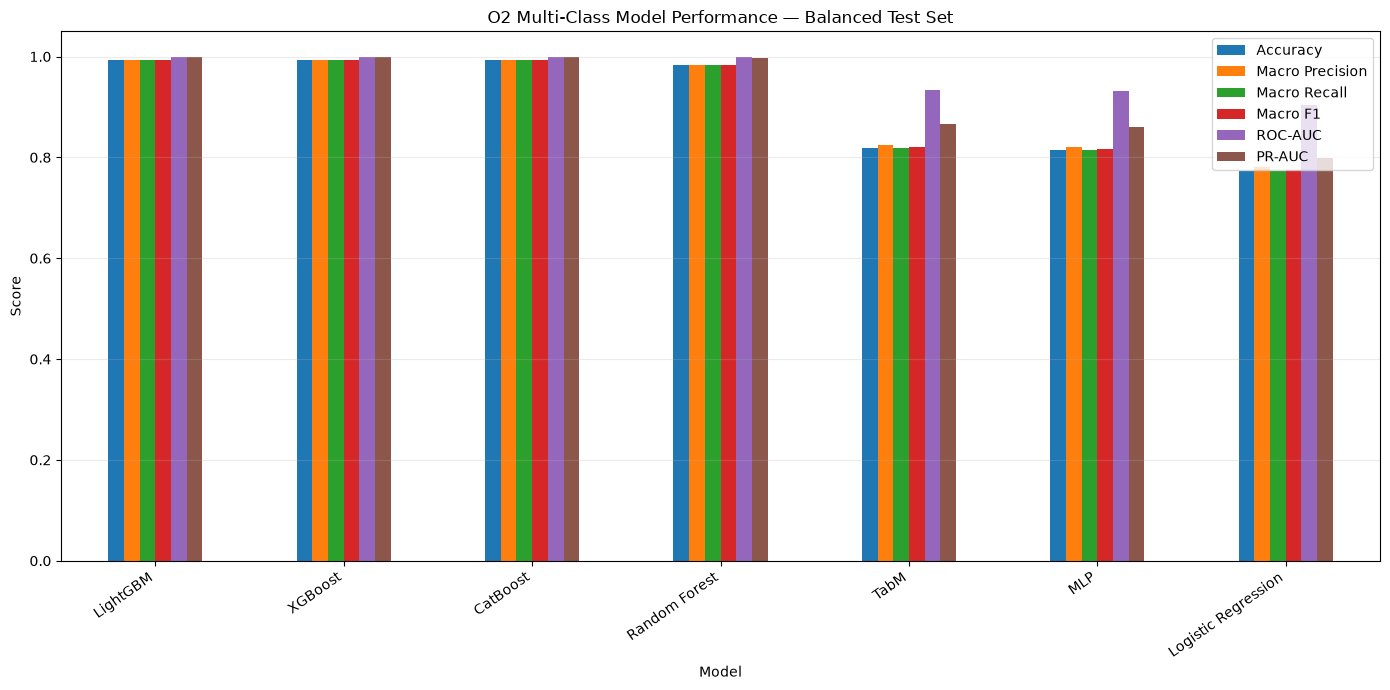

In [38]:
# ============================================================
# O2 VISUALIZATION 1 — MODEL PERFORMANCE COMPARISON
# ============================================================

metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "ROC-AUC",
    "PR-AUC"
]

plot_metrics = test_results.set_index("Model")[metrics_to_plot]

ax = plot_metrics.plot(
    kind="bar",
    figsize=(14, 7)
)

ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_title("O2 Multi-Class Model Performance — Balanced Test Set")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_model_performance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

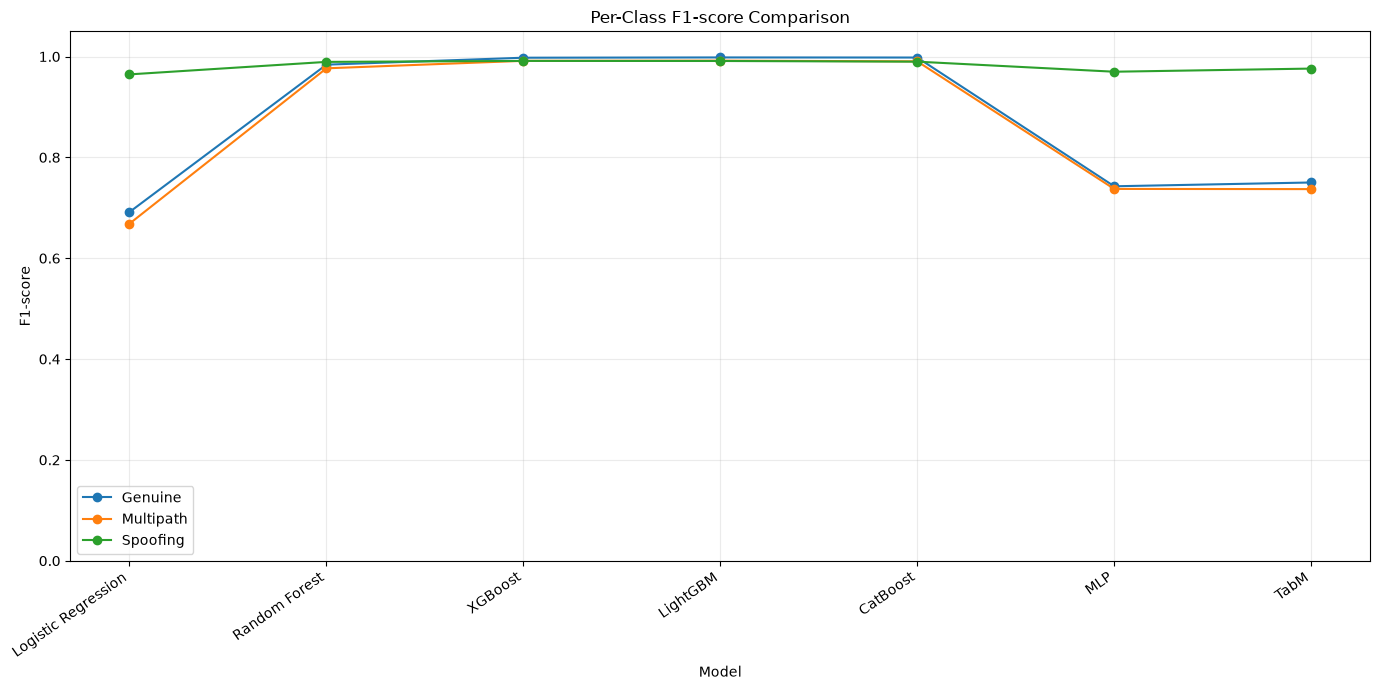

In [39]:
# ============================================================
# O2 VISUALIZATION 2 — PER-CLASS F1 / RECALL
# ============================================================

rows = []
for name, model in models.items():
    pred = test_cache[name]["pred"]
    report = classification_report(
        y_test,
        pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
    for cls in CLASS_NAMES:
        rows.append({
            "Model": name,
            "Class": cls,
            "Precision": report[cls]["precision"],
            "Recall": report[cls]["recall"],
            "F1": report[cls]["f1-score"]
        })

per_class_results = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(14, 7))
for cls in CLASS_NAMES:
    tmp = per_class_results[per_class_results["Class"] == cls]
    ax.plot(tmp["Model"], tmp["F1"], marker="o", label=cls)

ax.set_ylabel("F1-score")
ax.set_xlabel("Model")
ax.set_title("Per-Class F1-score Comparison")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.25)
ax.legend()
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

per_class_results.to_csv(O2_RESULT_DIR / "o2_per_class_metrics.csv", index=False)

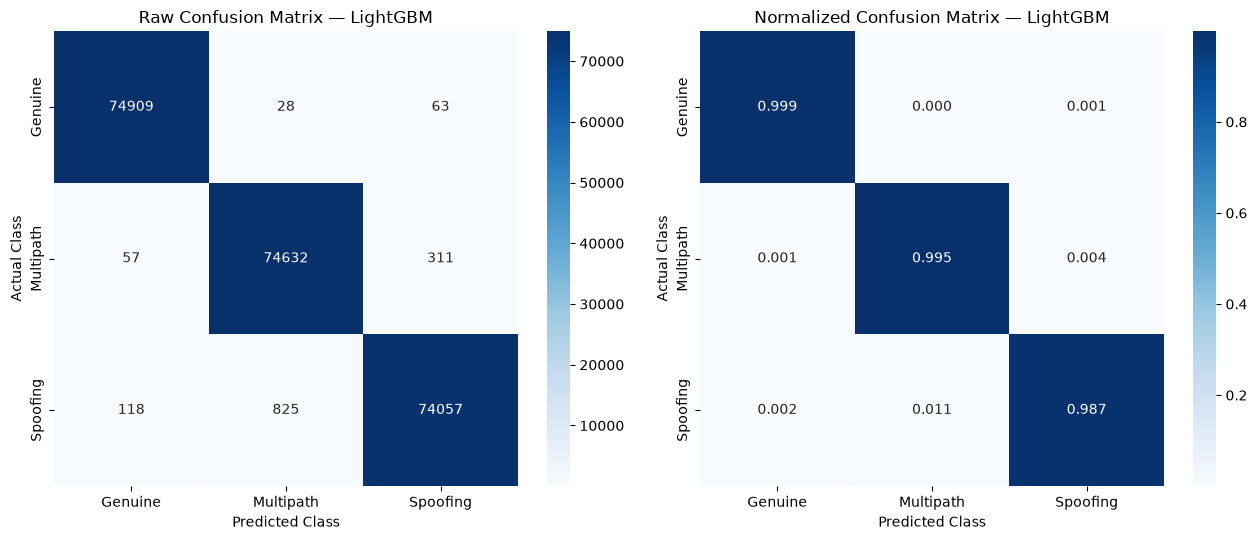

In [40]:
# ============================================================
# O2 VISUALIZATION 3 — RAW + NORMALIZED CONFUSION MATRICES
# ============================================================

import seaborn as sns

cm = confusion_matrix(y_test, test_pred)
cm_norm = confusion_matrix(y_test, test_pred, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0]
)
axes[0].set_title(f"Raw Confusion Matrix — {BEST_MODEL_NAME}")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

sns.heatmap(
    cm_norm, annot=True, fmt=".3f", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1]
)
axes[1].set_title(f"Normalized Confusion Matrix — {BEST_MODEL_NAME}")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

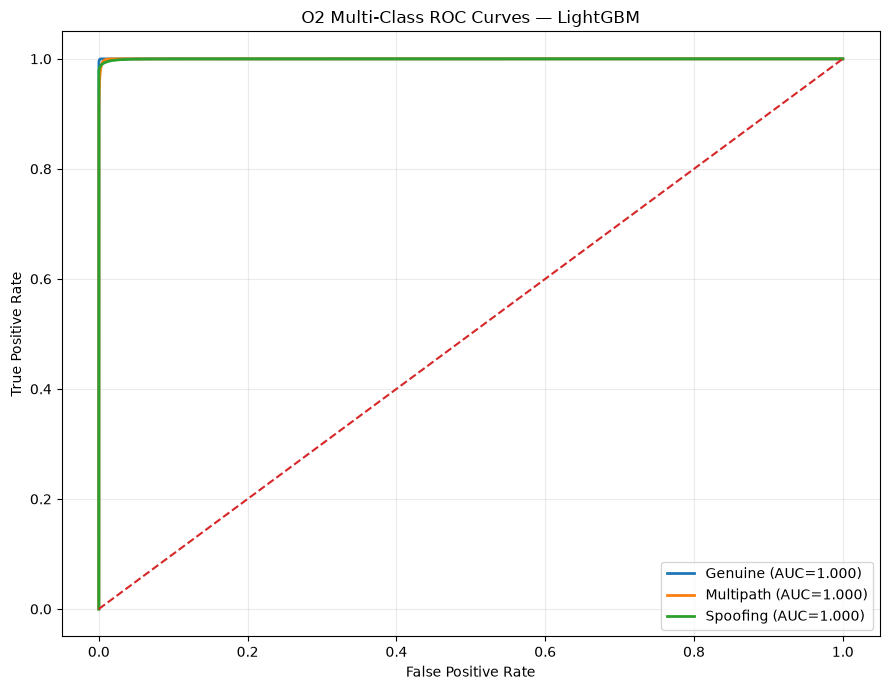

In [41]:
# ============================================================
# O2 VISUALIZATION 4 — MULTI-CLASS ROC CURVES
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        test_probability[:, i]
    )
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"{class_name} (AUC={roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"O2 Multi-Class ROC Curves — {BEST_MODEL_NAME}")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_multiclass_roc.png", dpi=300, bbox_inches="tight")
plt.show()

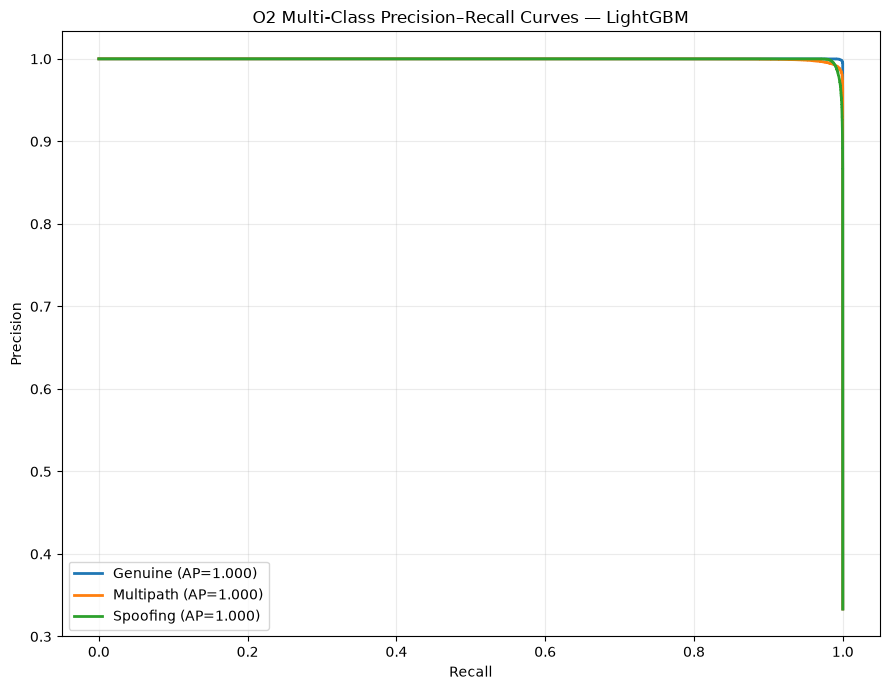

In [42]:
# ============================================================
# O2 VISUALIZATION 5 — PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        test_probability[:, i]
    )
    ap = average_precision_score(
        y_test_bin[:, i],
        test_probability[:, i]
    )
    plt.plot(
        recall, precision, linewidth=2,
        label=f"{class_name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"O2 Multi-Class Precision–Recall Curves — {BEST_MODEL_NAME}")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_multiclass_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

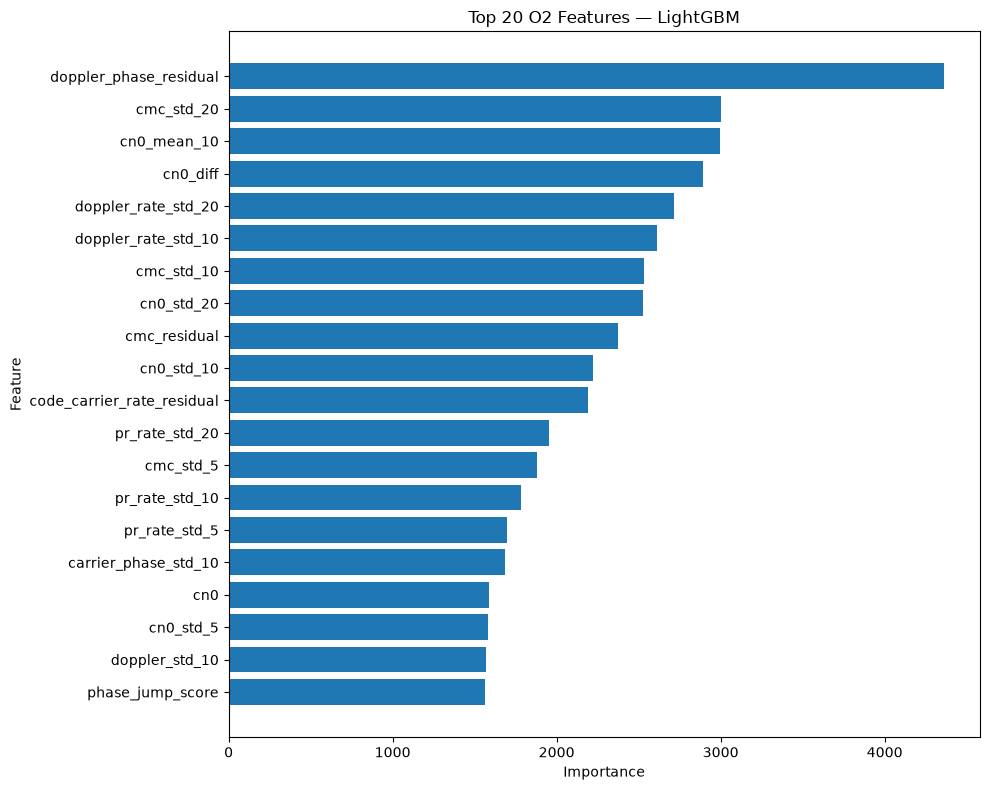

In [43]:
# ============================================================
# O2 VISUALIZATION 6 — FEATURE IMPORTANCE
# ============================================================

# Tree-based feature importance is shown whenever the selected model
# exposes feature_importances_. If the selected model is MLP/TabM,
# XGBoost is used as the common interpretable tree reference.

importance_model_name = BEST_MODEL_NAME
importance_model = BEST_MODEL

if not hasattr(importance_model, "feature_importances_"):
    importance_model_name = "XGBoost"
    importance_model = xgb_model

importance = pd.DataFrame({
    "Feature": O2_FEATURES,
    "Importance": importance_model.feature_importances_
}).sort_values("Importance", ascending=False)

top20 = importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top 20 O2 Features — {importance_model_name}")
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_feature_importance_top20.png", dpi=300, bbox_inches="tight")
plt.show()

importance.to_csv(O2_RESULT_DIR / "o2_feature_importance.csv", index=False)

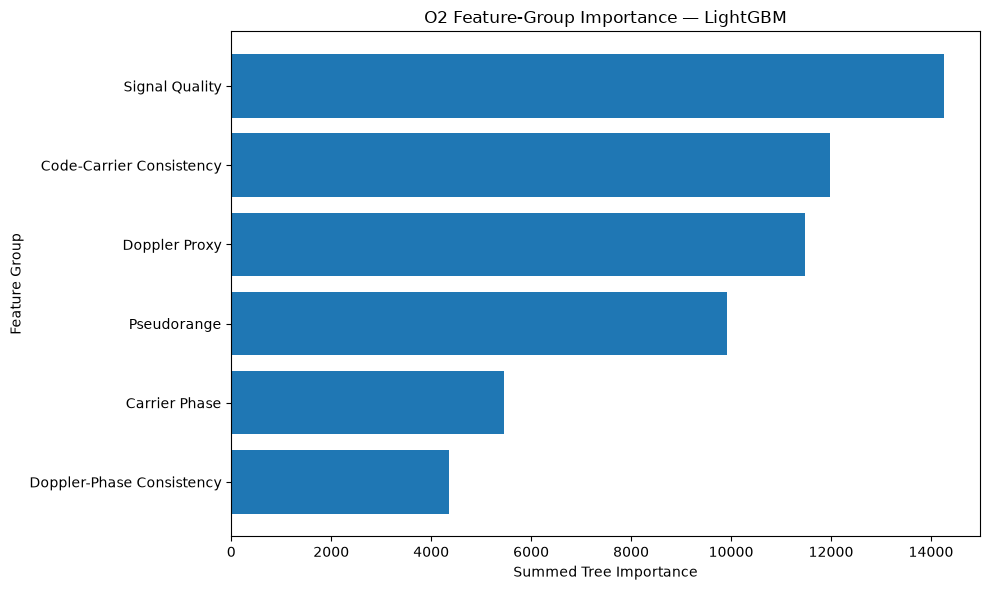

In [44]:
# ============================================================
# O2 VISUALIZATION 7 — FEATURE-GROUP IMPORTANCE
# ============================================================

FEATURE_GROUPS = {
    "Signal Quality": [
        "cn0", "cn0_diff", "cn0_rate", "cn0_std_10", "cn0_mean_10",
        "cn0_std_5", "cn0_std_20"
    ],
    "Pseudorange": [
        "pseudorange", "pseudorange_diff", "pseudorange_rate",
        "pseudorange_accel", "pseudorange_std_10",
        "pr_rate_std_5", "pr_rate_std_10", "pr_rate_std_20"
    ],
    "Carrier Phase": [
        "carrier_phase", "carrier_phase_diff", "carrier_phase_rate",
        "carrier_phase_accel", "carrier_phase_std_10", "phase_jump_score"
    ],
    "Doppler Proxy": [
        "doppler", "doppler_diff", "doppler_rate", "doppler_accel",
        "doppler_std_10", "doppler_jump_score", "doppler_rate_std_5",
        "doppler_rate_std_10", "doppler_rate_std_20"
    ],
    "Code-Carrier Consistency": [
        "cmc_residual", "cmc_std_10", "phase_range_rate_mps",
        "code_carrier_rate_residual", "cmc_std_5", "cmc_std_20"
    ],
    "Doppler-Phase Consistency": ["doppler_phase_residual"]
}

feature_to_group = {
    f: group
    for group, features in FEATURE_GROUPS.items()
    for f in features
}

importance["Group"] = importance["Feature"].map(feature_to_group).fillna("Other")
group_importance = (
    importance.groupby("Group", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

plt.figure(figsize=(10, 6))
plt.barh(
    group_importance["Group"][::-1],
    group_importance["Importance"][::-1]
)
plt.xlabel("Summed Tree Importance")
plt.ylabel("Feature Group")
plt.title(f"O2 Feature-Group Importance — {importance_model_name}")
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_feature_group_importance.png", dpi=300, bbox_inches="tight")
plt.show()

group_importance.to_csv(O2_RESULT_DIR / "o2_feature_group_importance.csv", index=False)

Running SHAP on LightGBM


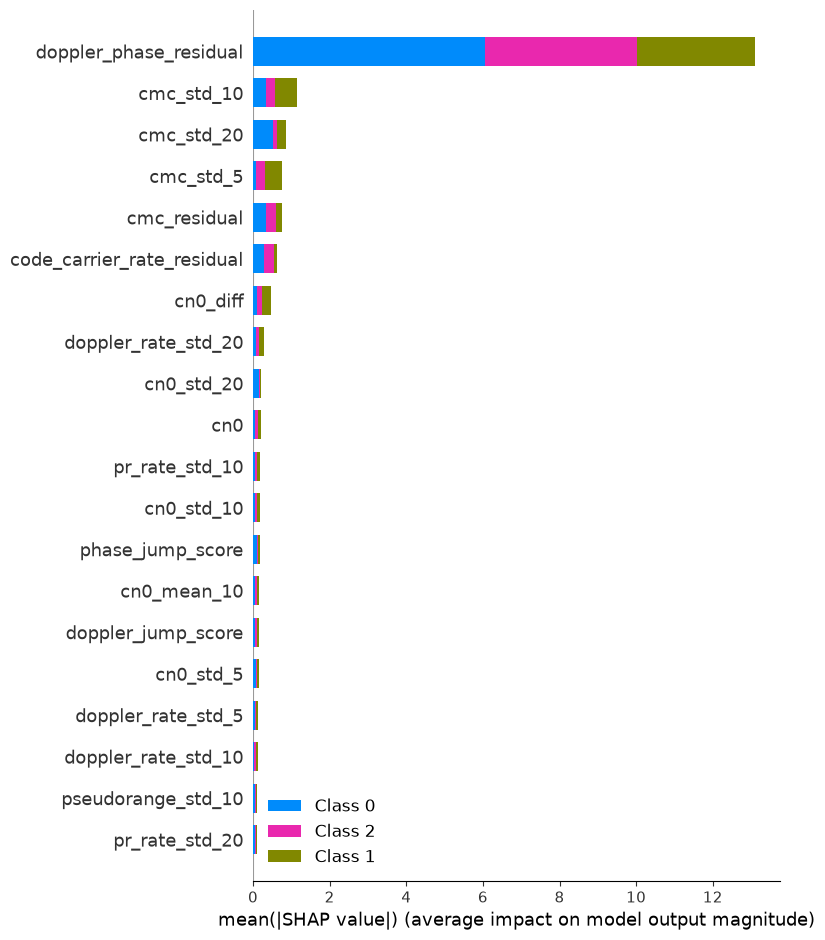

<Figure size 640x480 with 0 Axes>

In [45]:
# ============================================================
# O2 VISUALIZATION 8 — SHAP EXPLAINABILITY
# ============================================================

try:
    import shap

    shap_model = xgb_model if BEST_MODEL_NAME not in {"XGBoost", "LightGBM", "CatBoost"} else BEST_MODEL
    shap_sample = X_test.sample(
        n=min(5000, len(X_test)),
        random_state=RANDOM_STATE
    )

    print("Running SHAP on", BEST_MODEL_NAME if BEST_MODEL_NAME in {"XGBoost", "LightGBM", "CatBoost"} else "XGBoost reference")

    if BEST_MODEL_NAME == "XGBoost":
        explainer = shap.TreeExplainer(shap_model)
        shap_values = explainer(shap_sample)
        shap.summary_plot(shap_values, shap_sample, show=True)
        plt.savefig(O2_RESULT_DIR / "o2_shap_summary.png", dpi=300, bbox_inches="tight")
        plt.show()
    else:
        # Keep explainability model-independent by using XGBoost as a
        # common surrogate/reference for the engineered feature space.
        explainer = shap.TreeExplainer(xgb_model)
        shap_values = explainer(shap_sample)
        shap.summary_plot(shap_values, shap_sample, show=True)
        plt.savefig(O2_RESULT_DIR / "o2_shap_xgboost_reference.png", dpi=300, bbox_inches="tight")
        plt.show()

except Exception as e:
    print("SHAP skipped:", e)

  Station  Accuracy  Macro Precision  Macro Recall  Macro F1  Spoofing Recall
IISC00IND    0.9946           0.9946        0.9946    0.9946           0.9882
JDPR00IND    0.9955           0.9956        0.9955    0.9956           0.9887
LCK400IND    0.9911           0.9911        0.9911    0.9911           0.9852


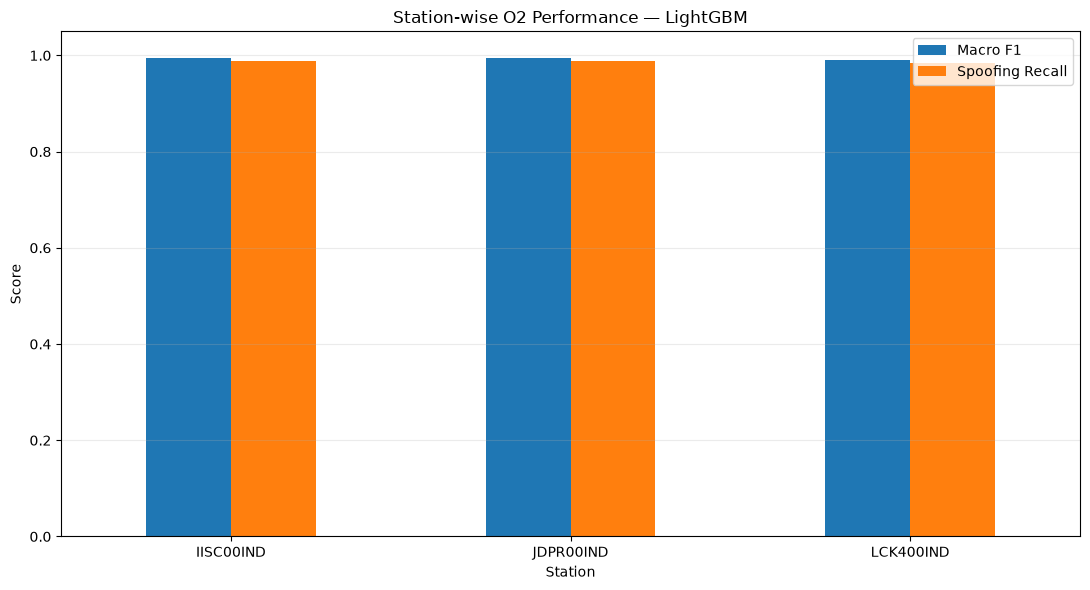

In [46]:
# ============================================================
# O2 VISUALIZATION 9 — STATION-WISE PERFORMANCE
# ============================================================

station_rows = []

for station in sorted(o2_test_model["station"].unique()):
    mask = o2_test_model["station"].to_numpy() == station
    y_s = y_test.to_numpy()[mask]
    p_s = test_pred[mask]

    station_rows.append({
        "Station": station,
        "Accuracy": accuracy_score(y_s, p_s),
        "Macro Precision": precision_score(y_s, p_s, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_s, p_s, average="macro", zero_division=0),
        "Macro F1": f1_score(y_s, p_s, average="macro", zero_division=0),
        "Spoofing Recall": recall_score(y_s, p_s, labels=[2], average="macro", zero_division=0)
    })

station_results = pd.DataFrame(station_rows)
print(station_results.round(4).to_string(index=False))

ax = station_results.set_index("Station")[["Macro F1", "Spoofing Recall"]].plot(
    kind="bar", figsize=(11, 6)
)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"Station-wise O2 Performance — {BEST_MODEL_NAME}")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_station_wise_performance.png", dpi=300, bbox_inches="tight")
plt.show()

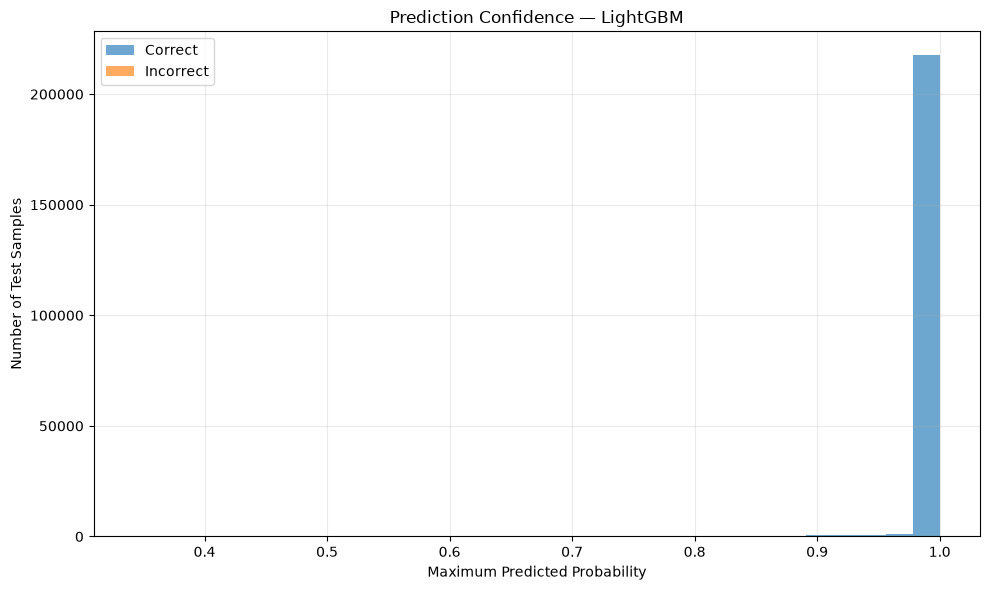

Mean confidence — correct: 0.9956832024752112
Mean confidence — incorrect: 0.7290270578861123


In [47]:
# ============================================================
# O2 VISUALIZATION 10 — PREDICTION CONFIDENCE
# ============================================================

confidence = np.max(test_probability, axis=1)
correct = test_pred == y_test.to_numpy()

plt.figure(figsize=(10, 6))
plt.hist(confidence[correct], bins=30, alpha=0.65, label="Correct")
plt.hist(confidence[~correct], bins=30, alpha=0.65, label="Incorrect")
plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Test Samples")
plt.title(f"Prediction Confidence — {BEST_MODEL_NAME}")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_prediction_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

print("Mean confidence — correct:", confidence[correct].mean())
print("Mean confidence — incorrect:", confidence[~correct].mean() if (~correct).any() else np.nan)

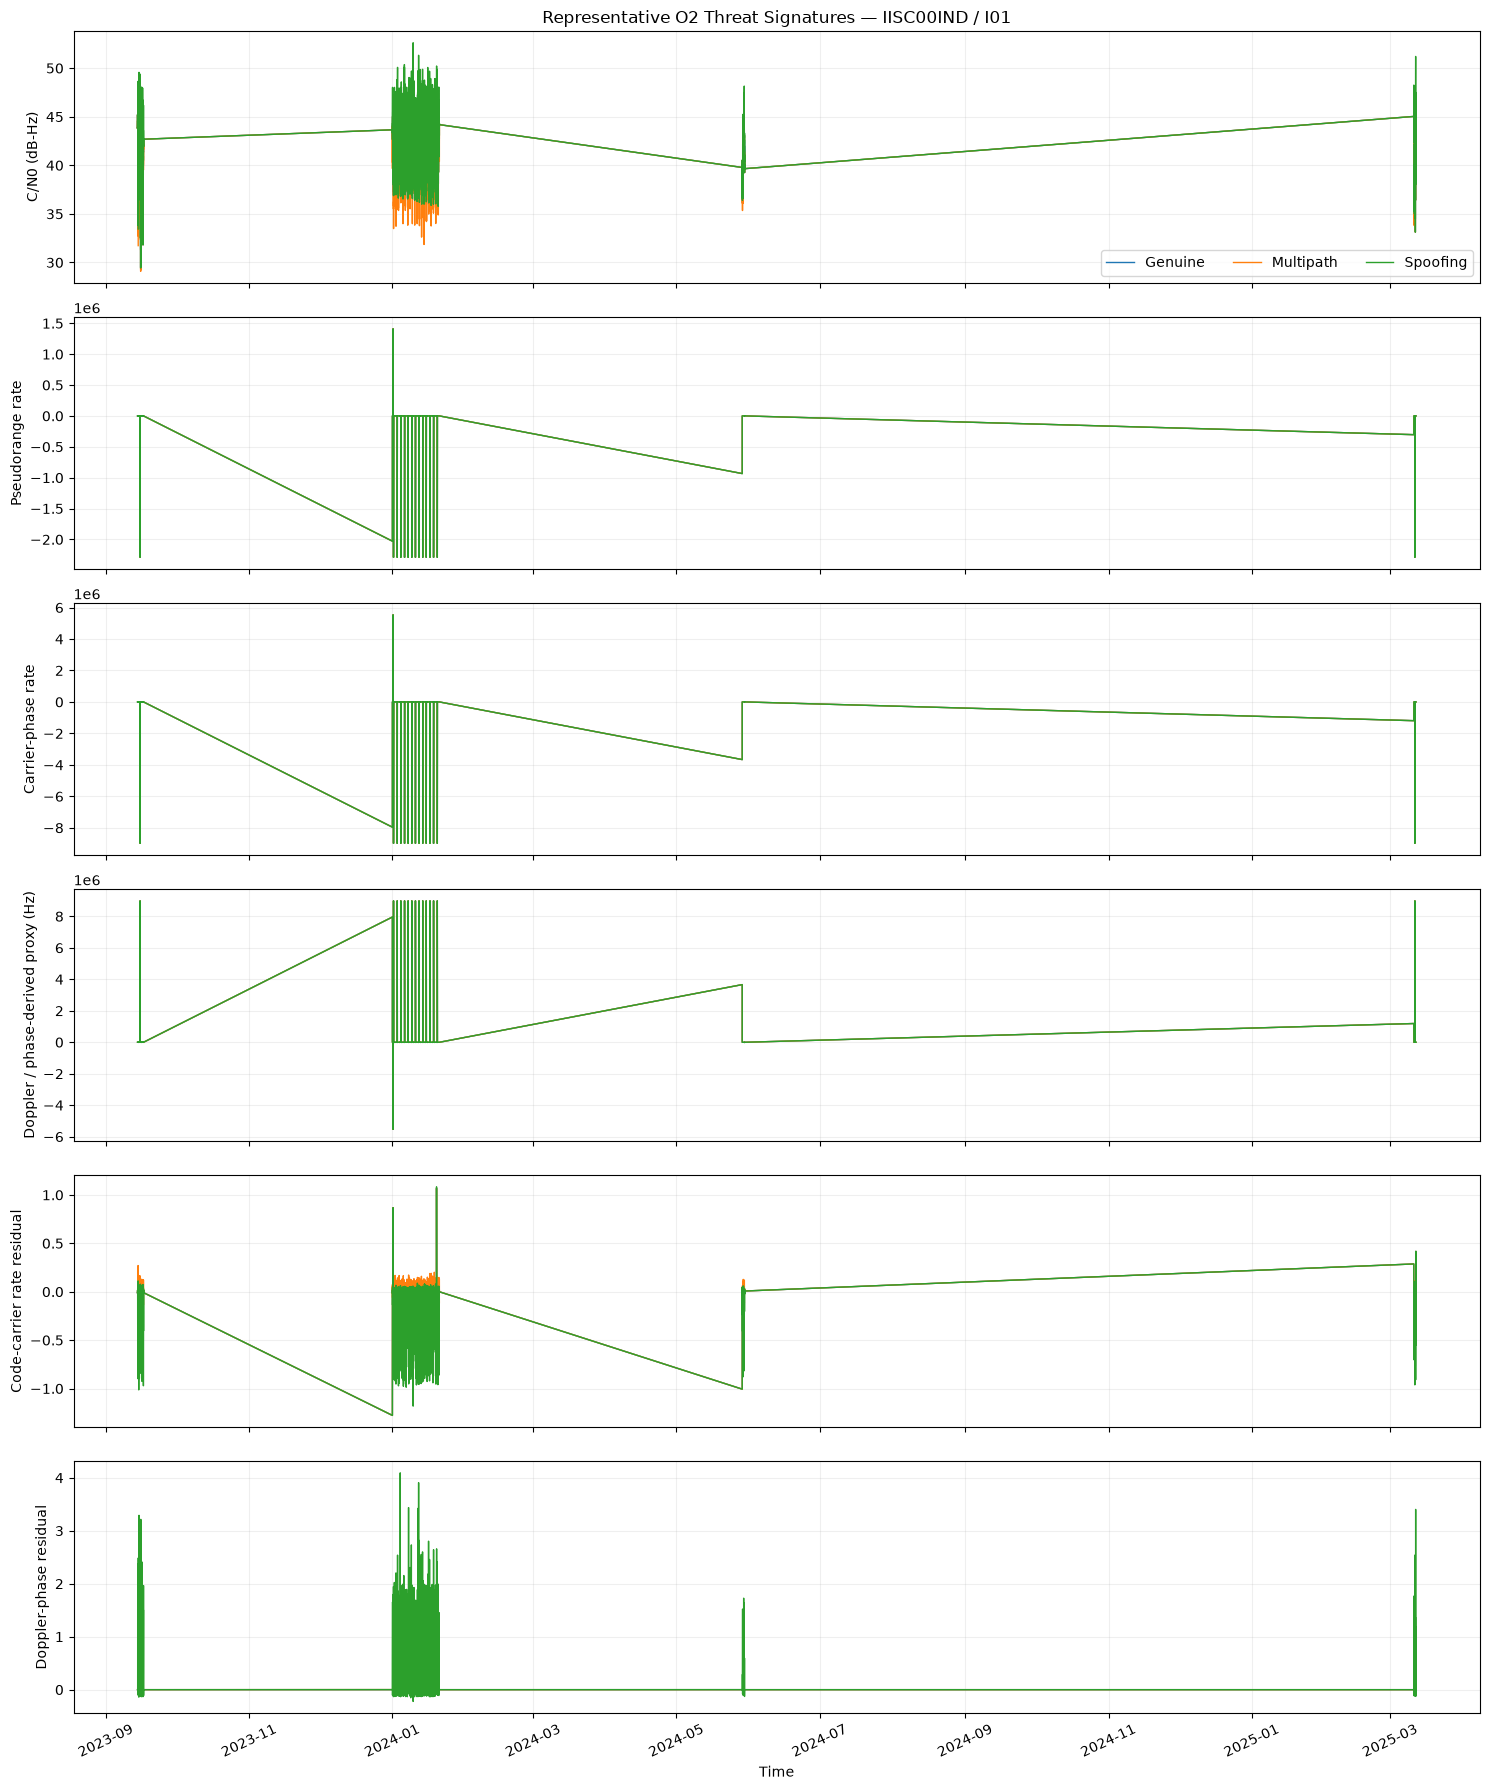

In [48]:
# ============================================================
# O2 VISUALIZATION 11 — REPRESENTATIVE MULTI-SIGNAL THREAT SIGNATURE
# ============================================================

REP_STATION = "IISC00IND"
REP_SV = "I01"

plot_df = o2_test[
    (o2_test["station"] == REP_STATION) &
    (o2_test["sv"] == REP_SV)
].copy()

if len(plot_df) == 0:
    # Fall back to the first available station/satellite pair.
    first = o2_test[["station", "sv"]].drop_duplicates().iloc[0]
    REP_STATION, REP_SV = first["station"], first["sv"]
    plot_df = o2_test[
        (o2_test["station"] == REP_STATION) &
        (o2_test["sv"] == REP_SV)
    ].copy()

# Select one scenario of each type so duplicated scenario trajectories
# are not overlaid on the same axes.
scenario_ids = plot_df.groupby("class_name")["scenario_id"].first().to_dict()

signals = [
    ("cn0", "C/N0 (dB-Hz)"),
    ("pseudorange_rate", "Pseudorange rate"),
    ("carrier_phase_rate", "Carrier-phase rate"),
    ("doppler", "Doppler / phase-derived proxy (Hz)"),
    ("code_carrier_rate_residual", "Code-carrier rate residual"),
    ("doppler_phase_residual", "Doppler-phase residual")
]

fig, axes = plt.subplots(6, 1, figsize=(15, 18), sharex=True)

for ax, (feature, ylabel) in zip(axes, signals):
    for cls in ["Genuine", "Multipath", "Spoofing"]:
        sid = scenario_ids.get(cls)
        if sid is None or feature not in plot_df.columns:
            continue
        tmp = plot_df[plot_df["scenario_id"] == sid].sort_values("time")
        ax.plot(tmp["time"], tmp[feature], label=cls, linewidth=1.0)

    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.2)

axes[0].set_title(
    f"Representative O2 Threat Signatures — {REP_STATION} / {REP_SV}"
)
axes[-1].set_xlabel("Time")
axes[0].legend(ncol=3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_threat_signal_signatures.png", dpi=300, bbox_inches="tight")
plt.show()

In [49]:
# ============================================================
# O2 — OPERATIONAL TEST PREDICTIONS
# ============================================================

# FAR and detection latency must be calculated on temporally ordered
# scenarios, not on the randomly balanced test sample. We therefore
# evaluate the validation-selected model on the complete chronological
# O2 test scenarios in chunks.

OPERATIONAL_BATCH_SIZE = 100_000


def predict_proba_chunked(model, X, batch_size=100_000):
    probs = []
    for start in range(0, len(X), batch_size):
        stop = min(start + batch_size, len(X))
        probs.append(model.predict_proba(X.iloc[start:stop]))
    return np.vstack(probs)


operational_X = o2_test[O2_FEATURES].astype(np.float32).copy()
operational_X = operational_X.replace([np.inf, -np.inf], np.nan)
operational_X = operational_X.fillna(train_medians)

print("Operational test rows:", f"{len(operational_X):,}")

t0 = time.perf_counter()
operational_probability = predict_proba_chunked(
    BEST_MODEL,
    operational_X,
    OPERATIONAL_BATCH_SIZE
)
operational_pred = np.argmax(operational_probability, axis=1)
operational_prediction_seconds = time.perf_counter() - t0

operational_eval = o2_test[
    ["time", "station", "sv", "scenario_id", "class_name", "attack_label"]
].copy()
operational_eval["predicted_class"] = operational_pred
operational_eval["predicted_label"] = pd.Series(operational_pred, index=operational_eval.index).map(CLASS_MAP).values
operational_eval["confidence"] = operational_probability.max(axis=1)

print(
    f"Operational prediction time: {operational_prediction_seconds:.2f} s"
)

Operational test rows: 3,014,472
Operational prediction time: 61.51 s


Selected Model  Overall FAR  False Multipath Alarm Rate  False Spoofing Alarm Rate  Genuine Samples
      LightGBM     0.001183                     0.00038                   0.000803          2419819

Station-wise FAR
  Station  Overall FAR  False Multipath Alarm Rate  False Spoofing Alarm Rate
IISC00IND     0.000424                    0.000093                   0.000332
JDPR00IND     0.000503                    0.000048                   0.000455
LCK400IND     0.003130                    0.001160                   0.001970


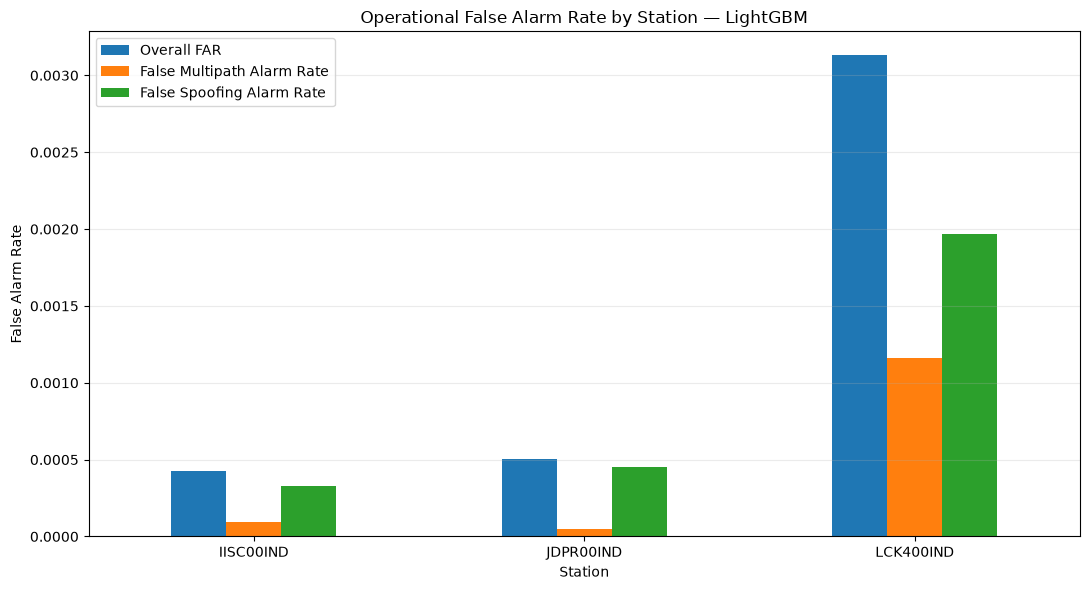

In [50]:
# ============================================================
# O2 OPERATIONAL METRIC 1 — FALSE ALARM RATES
# ============================================================

# Operational definition:
# FAR = fraction of genuinely clean observations that trigger any
# threat alarm. Additional class-specific rates are also reported.

genuine = operational_eval[operational_eval["attack_label"] == 0]

false_alarm_any = genuine["predicted_class"].isin([1, 2])
false_multipath = genuine["predicted_class"] == 1
false_spoofing = genuine["predicted_class"] == 2

far_metrics = pd.DataFrame([{
    "Selected Model": BEST_MODEL_NAME,
    "Overall FAR": false_alarm_any.mean(),
    "False Multipath Alarm Rate": false_multipath.mean(),
    "False Spoofing Alarm Rate": false_spoofing.mean(),
    "Genuine Samples": len(genuine)
}])

print(far_metrics.round(6).to_string(index=False))
far_metrics.to_csv(O2_RESULT_DIR / "o2_false_alarm_rates.csv", index=False)

# Station-wise FAR
far_station = []
for station, g in genuine.groupby("station"):
    far_station.append({
        "Station": station,
        "Overall FAR": g["predicted_class"].isin([1, 2]).mean(),
        "False Multipath Alarm Rate": (g["predicted_class"] == 1).mean(),
        "False Spoofing Alarm Rate": (g["predicted_class"] == 2).mean()
    })

far_station = pd.DataFrame(far_station)
print("\nStation-wise FAR")
print(far_station.round(6).to_string(index=False))

far_station.set_index("Station").plot(
    kind="bar", figsize=(11, 6)
)
plt.ylabel("False Alarm Rate")
plt.title(f"Operational False Alarm Rate by Station — {BEST_MODEL_NAME}")
plt.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_far_by_station.png", dpi=300, bbox_inches="tight")
plt.show()

Detection episodes detected: 10680
               count   mean      std   min   25%   50%   75%       max
attack_class                                                          
Multipath     6192.0  66.69  2136.56  30.0  30.0  30.0  30.0  164400.0
Spoofing      4488.0  51.72    26.03  30.0  30.0  60.0  60.0     600.0


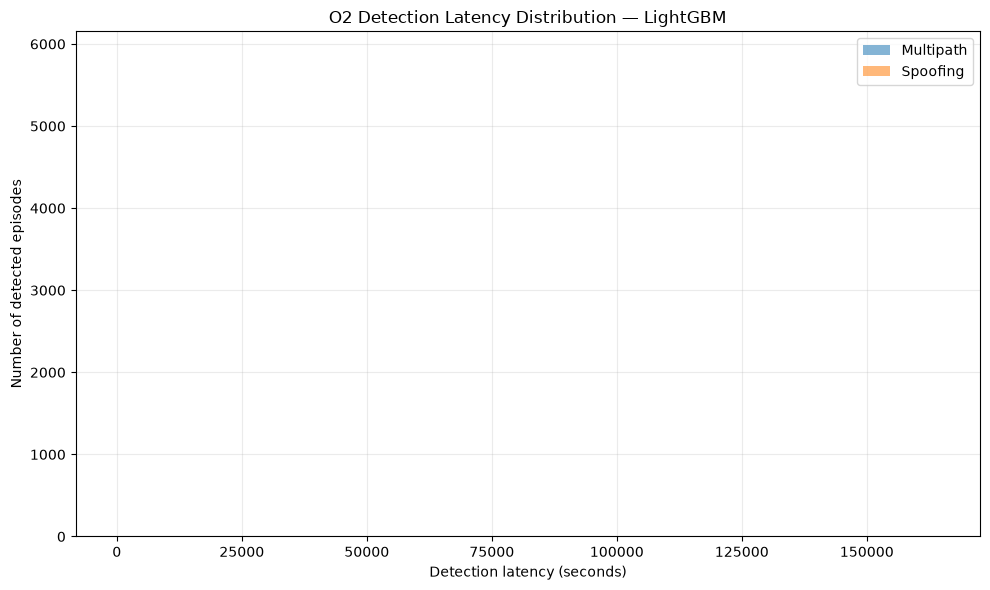


Latency summary
attack_class  episodes  mean_latency_s  median_latency_s  p95_latency_s  detection_rate  total_episodes
   Multipath      6192          66.686              30.0           60.0             1.0            6192
    Spoofing      4488          51.718              60.0           90.0             1.0            4488


In [51]:
# ============================================================
# O2 OPERATIONAL METRIC 2 — DETECTION LATENCY
# ============================================================

# A robust alarm is defined as TWO consecutive correct threat predictions.
# With 30-second sampling, the measured latency is quantized by the
# observation cadence. Latency is attack-onset-to-persistent-correct-alarm,
# not raw model inference runtime.

PERSISTENCE = 2
SAMPLE_INTERVAL_SECONDS = 30


def episode_latency(group, attack_class, persistence=2):
    g = group.sort_values("time").reset_index(drop=True)
    attack_mask = g["attack_label"].to_numpy() == attack_class
    pred = g["predicted_class"].to_numpy()
    times = pd.to_datetime(g["time"]).to_numpy()

    latencies = []
    i = 0
    n = len(g)

    while i < n:
        if not attack_mask[i]:
            i += 1
            continue

        start = i
        while i < n and attack_mask[i]:
            i += 1
        end = i

        correct = pred[start:end] == attack_class
        detected_at = None

        for j in range(0, len(correct) - persistence + 1):
            if np.all(correct[j:j + persistence]):
                detected_at = start + j + persistence - 1
                break

        if detected_at is not None:
            latency = (
                pd.Timestamp(times[detected_at]) -
                pd.Timestamp(times[start])
            ).total_seconds()
            latencies.append({
                "attack_class": CLASS_MAP[attack_class],
                "attack_start": pd.Timestamp(times[start]),
                "detection_time": pd.Timestamp(times[detected_at]),
                "latency_seconds": latency,
                "attack_duration_seconds": (
                    pd.Timestamp(times[end - 1]) -
                    pd.Timestamp(times[start])
                ).total_seconds(),
                "station": g.loc[0, "station"],
                "sv": g.loc[0, "sv"],
                "scenario_id": g.loc[0, "scenario_id"]
            })

    return latencies


latency_rows = []

for (station, sv, scenario_id), g in operational_eval.groupby(
    ["station", "sv", "scenario_id"], sort=False
):
    attack_classes = sorted(
        set(g["attack_label"].astype(int).unique()) - {0}
    )
    for cls in attack_classes:
        latency_rows.extend(
            episode_latency(g, int(cls), persistence=PERSISTENCE)
        )

latency_results = pd.DataFrame(latency_rows)

if len(latency_results):
    print("Detection episodes detected:", len(latency_results))
    print(latency_results.groupby("attack_class")["latency_seconds"].describe().round(2))

    latency_results.to_csv(
        O2_RESULT_DIR / "o2_detection_latency_by_episode.csv",
        index=False
    )

    plt.figure(figsize=(10, 6))
    for cls in ["Multipath", "Spoofing"]:
        tmp = latency_results[latency_results["attack_class"] == cls]
        if len(tmp):
            plt.hist(
                tmp["latency_seconds"],
                bins=np.arange(-15, tmp["latency_seconds"].max() + 45, 30),
                alpha=0.55,
                label=cls
            )
    plt.xlabel("Detection latency (seconds)")
    plt.ylabel("Number of detected episodes")
    plt.title(f"O2 Detection Latency Distribution — {BEST_MODEL_NAME}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(O2_RESULT_DIR / "o2_detection_latency_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    latency_summary = (
        latency_results.groupby("attack_class")
        .agg(
            episodes=("latency_seconds", "count"),
            mean_latency_s=("latency_seconds", "mean"),
            median_latency_s=("latency_seconds", "median"),
            p95_latency_s=("latency_seconds", lambda x: np.percentile(x, 95)),
            detection_rate=("latency_seconds", lambda x: len(x))
        )
        .reset_index()
    )

    # Detection rate denominator is the number of attack episodes, computed
    # separately below because undetected episodes are not present in the table.
    episode_counts = []
    for (station, sv, scenario_id), g in operational_eval.groupby(
        ["station", "sv", "scenario_id"], sort=False
    ):
        attack_classes = sorted(
            set(g["attack_label"].astype(int).unique()) - {0}
        )
        for cls in attack_classes:
            mask = g["attack_label"].to_numpy() == cls
            count = 0
            i = 0
            while i < len(mask):
                if not mask[i]:
                    i += 1
                    continue
                count += 1
                while i < len(mask) and mask[i]:
                    i += 1
            episode_counts.append({"attack_class": CLASS_MAP[cls], "total_episodes": count})

    episode_counts = pd.DataFrame(episode_counts).groupby("attack_class", as_index=False)["total_episodes"].sum()
    latency_summary = latency_summary.merge(episode_counts, on="attack_class", how="left")
    latency_summary["detection_rate"] = latency_summary["episodes"] / latency_summary["total_episodes"]

    print("\nLatency summary")
    print(latency_summary.round(3).to_string(index=False))
    latency_summary.to_csv(O2_RESULT_DIR / "o2_detection_latency_summary.csv", index=False)

else:
    print("No persistent attack detections were found under the current rule.")

<Figure size 1000x600 with 0 Axes>

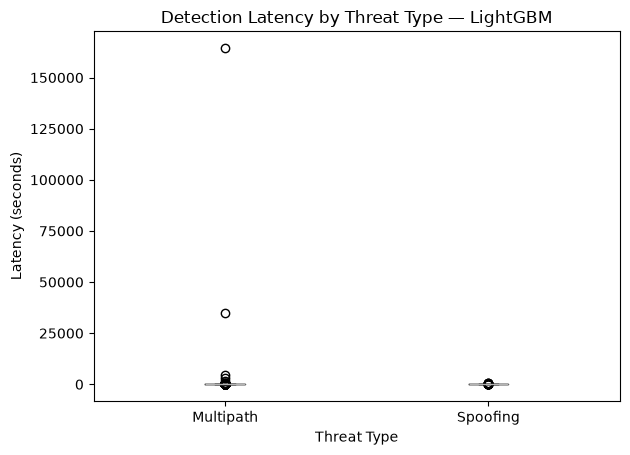

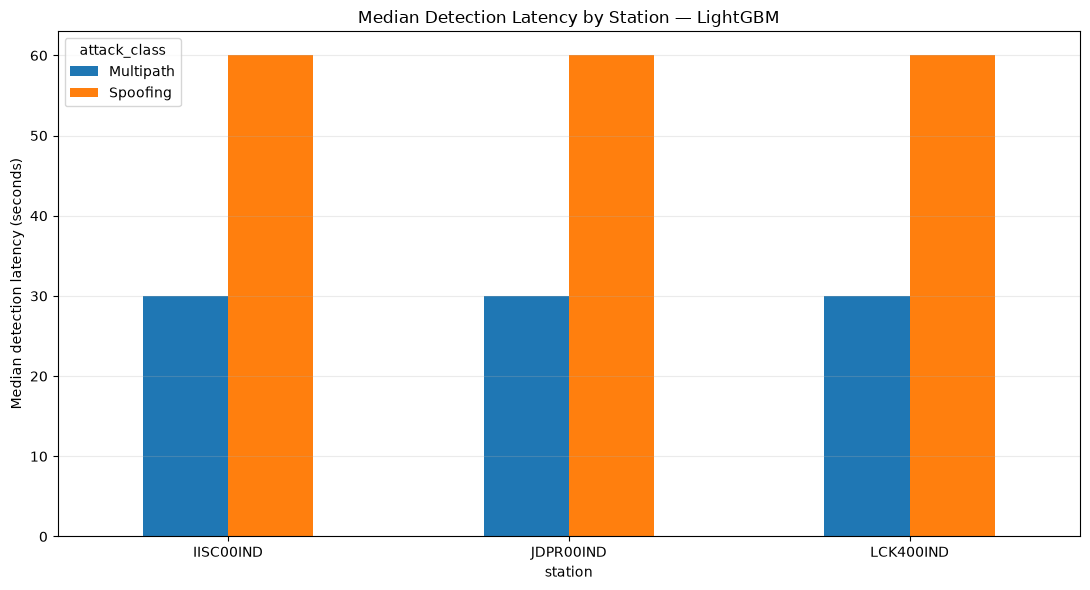

In [52]:
# ============================================================
# O2 VISUALIZATION 12 — DETECTION LATENCY BY THREAT TYPE / STATION
# ============================================================

if len(latency_results):
    plt.figure(figsize=(10, 6))
    latency_results.boxplot(
        column="latency_seconds",
        by="attack_class",
        grid=False
    )
    plt.suptitle("")
    plt.title(f"Detection Latency by Threat Type — {BEST_MODEL_NAME}")
    plt.xlabel("Threat Type")
    plt.ylabel("Latency (seconds)")
    plt.tight_layout()
    plt.savefig(O2_RESULT_DIR / "o2_latency_by_threat_type.png", dpi=300, bbox_inches="tight")
    plt.show()

    station_latency = (
        latency_results.groupby(["station", "attack_class"])["latency_seconds"]
        .median()
        .unstack(fill_value=np.nan)
    )

    station_latency.plot(kind="bar", figsize=(11, 6))
    plt.ylabel("Median detection latency (seconds)")
    plt.title(f"Median Detection Latency by Station — {BEST_MODEL_NAME}")
    plt.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(O2_RESULT_DIR / "o2_latency_by_station.png", dpi=300, bbox_inches="tight")
    plt.show()

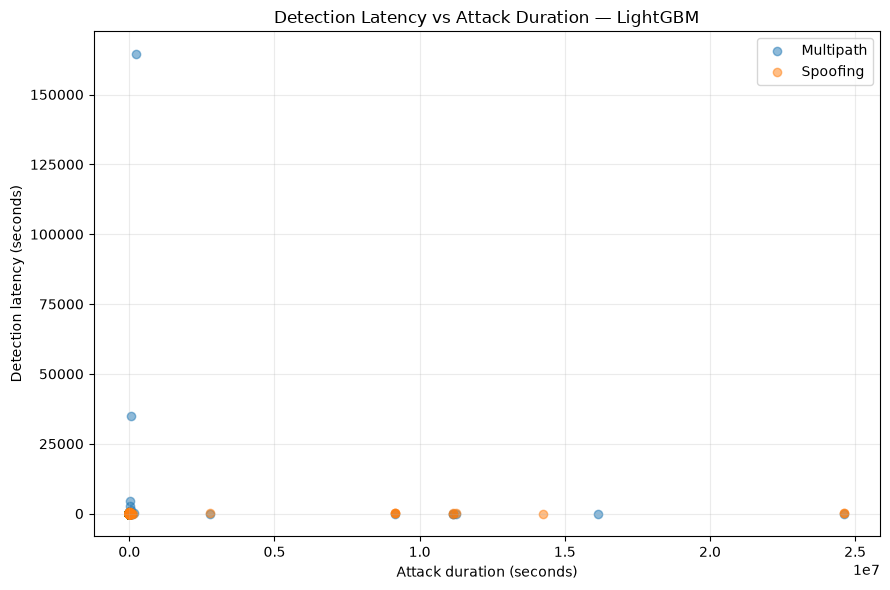

In [53]:
# ============================================================
# O2 VISUALIZATION 13 — DETECTION LATENCY VS ATTACK DURATION
# ============================================================

if len(latency_results):
    plt.figure(figsize=(9, 6))
    for cls in ["Multipath", "Spoofing"]:
        tmp = latency_results[latency_results["attack_class"] == cls]
        if len(tmp):
            plt.scatter(
                tmp["attack_duration_seconds"],
                tmp["latency_seconds"],
                alpha=0.5,
                label=cls
            )
    plt.xlabel("Attack duration (seconds)")
    plt.ylabel("Detection latency (seconds)")
    plt.title(f"Detection Latency vs Attack Duration — {BEST_MODEL_NAME}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(O2_RESULT_DIR / "o2_latency_vs_attack_duration.png", dpi=300, bbox_inches="tight")
    plt.show()

              Model  Samples  Inference ms/sample  Inference samples/s
Logistic Regression    50000             0.000225         4.446025e+06
                MLP    50000             0.001553         6.437625e+05
           CatBoost    50000             0.001921         5.205237e+05
      Random Forest    50000             0.006506         1.537154e+05
            XGBoost    50000             0.006843         1.461304e+05
               TabM    50000             0.017209         5.810919e+04
           LightGBM    50000             0.017731         5.639937e+04


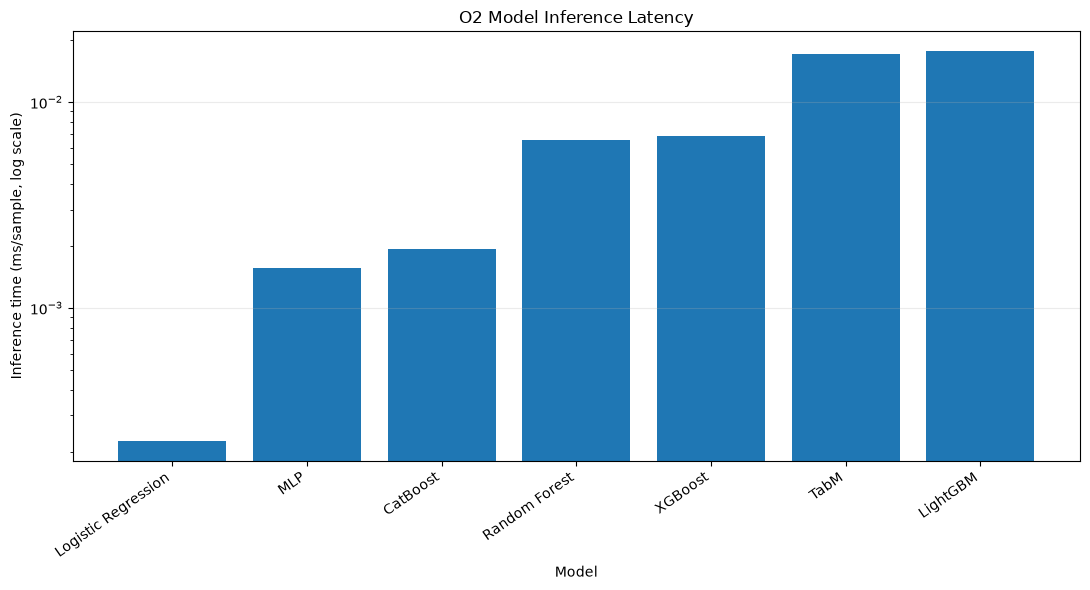

In [54]:
# ============================================================
# O2 VISUALIZATION 14 — INFERENCE LATENCY
# ============================================================

latency_rows = []
for name, model in models.items():
    sample = X_test.iloc[:min(50_000, len(X_test))]
    t0 = time.perf_counter()
    _ = model.predict(sample)
    elapsed = time.perf_counter() - t0
    latency_rows.append({
        "Model": name,
        "Samples": len(sample),
        "Inference ms/sample": elapsed / len(sample) * 1000,
        "Inference samples/s": len(sample) / max(elapsed, 1e-9)
    })

inference_results = pd.DataFrame(latency_rows).sort_values("Inference ms/sample")
print(inference_results.round(6).to_string(index=False))

plt.figure(figsize=(11, 6))
plt.bar(
    inference_results["Model"],
    inference_results["Inference ms/sample"]
)
plt.yscale("log")
plt.ylabel("Inference time (ms/sample, log scale)")
plt.xlabel("Model")
plt.title("O2 Model Inference Latency")
plt.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(O2_RESULT_DIR / "o2_inference_latency.png", dpi=300, bbox_inches="tight")
plt.show()

In [55]:
# ============================================================
# O2 — SAVE BENCHMARKS / MODELS / OUTPUTS
# ============================================================

validation_results.to_csv(
    O2_RESULT_DIR / "o2_validation_benchmark.csv",
    index=False
)

test_results.to_csv(
    O2_RESULT_DIR / "o2_final_test_benchmark_all_models.csv",
    index=False
)

inference_results.to_csv(
    O2_RESULT_DIR / "o2_inference_latency.csv",
    index=False
)

# Save the selected model and feature list.
joblib.dump(
    BEST_MODEL,
    O2_MODEL_DIR / "o2_best_classifier.pkl"
)

joblib.dump(
    O2_FEATURES,
    O2_MODEL_DIR / "o2_feature_list.pkl"
)

# Save all sklearn/tree models where serialization is supported.
for name, model in models.items():
    if name == "TabM":
        try:
            torch.save(
                {
                    "state_dict": model.model.state_dict(),
                    "mean": model.mean_,
                    "std": model.std_,
                    "n_features": model.n_features,
                    "n_classes": model.n_classes,
                    "k": model.k
                },
                O2_MODEL_DIR / "o2_tabm_checkpoint.pt"
            )
        except Exception as e:
            print("TabM checkpoint save skipped:", e)
    else:
        safe_name = name.lower().replace(" ", "_")
        joblib.dump(
            model,
            O2_MODEL_DIR / f"o2_{safe_name}.pkl"
        )

print("Saved O2 benchmark, models and visualisation outputs to:")
print(O2_RESULT_DIR.resolve())
print(O2_MODEL_DIR.resolve())

Saved O2 benchmark, models and visualisation outputs to:
D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o2\results
D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o2\models


In [56]:
# ============================================================
# O2 — SAVE BALANCED TEST PREDICTIONS
# ============================================================

o2_predictions = o2_test_model[["time", "station", "sv", "scenario_id"]].copy()
o2_predictions["actual_class"] = y_test.to_numpy()
o2_predictions["predicted_class"] = test_pred
o2_predictions["actual_label"] = o2_predictions["actual_class"].map(CLASS_MAP)
o2_predictions["predicted_label"] = o2_predictions["predicted_class"].map(CLASS_MAP)

o2_predictions["confidence"] = test_probability.max(axis=1)

if test_probability is not None:
    o2_predictions["genuine_probability"] = test_probability[:, 0]
    o2_predictions["multipath_probability"] = test_probability[:, 1]
    o2_predictions["spoofing_probability"] = test_probability[:, 2]

o2_predictions.to_parquet(
    O2_RESULT_DIR / "o2_threat_detection_output_balanced_test.parquet",
    index=False
)

# Full chronological operational output.
operational_eval.to_parquet(
    O2_RESULT_DIR / "o2_operational_test_predictions.parquet",
    index=False
)

print(o2_predictions.head())

                 time    station   sv                   scenario_id  \
0 2022-12-15 23:12:00  LCK400IND  I04   LCK400IND_I04_test_spoofing   
1 2023-09-09 07:04:00  IISC00IND  I05  IISC00IND_I05_test_multipath   
2 2024-01-17 09:08:30  IISC00IND  I03  IISC00IND_I03_test_multipath   
3 2023-09-16 15:34:30  IISC00IND  I06  IISC00IND_I06_test_multipath   
4 2024-01-19 00:08:00  LCK400IND  I03   LCK400IND_I03_test_spoofing   

   actual_class  predicted_class actual_label predicted_label  confidence  \
0             2                2     Spoofing        Spoofing    0.999997   
1             1                1    Multipath       Multipath    0.999769   
2             1                2    Multipath        Spoofing    0.553621   
3             1                1    Multipath       Multipath    0.997920   
4             2                2     Spoofing        Spoofing    0.999998   

   genuine_probability  multipath_probability  spoofing_probability  
0         1.036519e-07               0.0

In [57]:
# ============================================================
# O2 — SEQUENCE WINDOW PREPARATION FOR MINIROCKET / HYDRA
# ============================================================
import numpy as np
import pandas as pd
import time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

SEQ_LEN = 20              # 20 x 30-second epochs = 10-minute window
SEQ_STRIDE = 5             # start a new window every 2.5 minutes
MAX_WINDOWS_PER_CLASS = {"train": 3000, "val": 1000, "test": 1000}
SEQ_FEATURES = list(O2_FEATURES)
SEQ_RANDOM_STATE = int(globals().get("RANDOM_STATE", 42))

def build_o2_sequence_windows(frame, split_name, seq_len=SEQ_LEN, stride=SEQ_STRIDE,
                              max_per_class=None, random_state=SEQ_RANDOM_STATE):
    required = {"scenario_id", "station", "sv", "time", "attack_label", *SEQ_FEATURES}
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError(f"Missing required columns for sequence windows: {missing}")

    rng = np.random.default_rng(random_state)
    windows_by_class = {int(c): [] for c in sorted(frame["attack_label"].dropna().astype(int).unique())}
    group_cols = [c for c in ["scenario_id", "station", "sv"] if c in frame.columns]
    # Sort each stream chronologically; never combine windows across streams.
    for _, group in frame.sort_values("time").groupby(group_cols, sort=False, dropna=False):
        group = group.sort_values("time")
        x = group[SEQ_FEATURES].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=np.float32)
        y = group["attack_label"].to_numpy(dtype=np.int64)
        if len(group) < seq_len:
            continue
        # Fill feature gaps locally within this stream; any remaining gaps become zero.
        x = pd.DataFrame(x).ffill().bfill().fillna(0.0).to_numpy(dtype=np.float32)
        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            labels = y[start:end]
            # Keep only pure windows so a window does not straddle an attack transition.
            if np.all(labels == labels[0]):
                cls = int(labels[-1])
                windows_by_class.setdefault(cls, []).append(x[start:end].T)

    X_parts, y_parts = [], []
    for cls, windows in windows_by_class.items():
        if not windows:
            continue
        if max_per_class is not None and len(windows) > max_per_class:
            chosen = rng.choice(len(windows), size=max_per_class, replace=False)
            windows = [windows[i] for i in chosen]
        X_parts.extend(windows)
        y_parts.extend([cls] * len(windows))
    if not X_parts:
        raise ValueError(f"No pure sequence windows were created for {split_name}. Check scenario lengths/labels.")
    X_out = np.asarray(X_parts, dtype=np.float32)
    y_out = np.asarray(y_parts, dtype=np.int64)
    order = rng.permutation(len(y_out))
    return X_out[order], y_out[order]

sequence_sources = {
    "train": o2_train_model,
    "val": o2_val_model,
    "test": o2_test_model,
}
sequence_data = {}
for split_name, split_frame in sequence_sources.items():
    t0 = time.perf_counter()
    X_seq, y_seq = build_o2_sequence_windows(
        split_frame, split_name,
        max_per_class=MAX_WINDOWS_PER_CLASS[split_name],
        random_state=SEQ_RANDOM_STATE + {"train": 0, "val": 1, "test": 2}[split_name]
    )
    sequence_data[split_name] = (X_seq, y_seq)
    print(f"{split_name}: X={X_seq.shape}, y={y_seq.shape}, built in {time.perf_counter()-t0:.1f}s")
    print(" class counts:", dict(zip(*np.unique(y_seq, return_counts=True))))


train: X=(9000, 37, 20), y=(9000,), built in 4.3s
 class counts: {np.int64(0): np.int64(3000), np.int64(1): np.int64(3000), np.int64(2): np.int64(3000)}
val: X=(3000, 37, 20), y=(3000,), built in 1.1s
 class counts: {np.int64(0): np.int64(1000), np.int64(1): np.int64(1000), np.int64(2): np.int64(1000)}
test: X=(3000, 37, 20), y=(3000,), built in 0.8s
 class counts: {np.int64(0): np.int64(1000), np.int64(1): np.int64(1000), np.int64(2): np.int64(1000)}


In [69]:
%pip install interpret

     ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
     ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
     ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
     ----- ---------------------------------- 0.5/4.0 MB 2.4 MB/s eta 0:00:02
     ------- -------------------------------- 0.8/4.0 MB 2.2 MB/s eta 0:00:02
     ------------- -------------------------- 1.3/4.0 MB 2.2 MB/s eta 0:00:02
     --------------------- ------------------ 2.1/4.0 MB 2.7 MB/s eta 0:00:01
     ---------------------------- ----------- 2.9/4.0 MB 2.9 MB/s eta 0:00:01
     ------------------------------------ --- 3.7/4.0 MB 3.0 MB/s eta 0:00:01
     ---------------------------------------- 4.0/4.0 MB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached retrying-1.4.2-py3-none-any.whl.metadata (5.5 kB)
  Using cach


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [70]:
import time
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

ebm_model = ExplainableBoostingClassifier(
    max_bins=64,
    max_interaction_bins=16,
    interactions=10,
    outer_bags=4,
    validation_size=0.15,
    learning_rate=0.03,
    max_rounds=1000,
    random_state=42,
    n_jobs=-1
)

print("Training EBM...")
start = time.perf_counter()

ebm_model.fit(X_train, y_train)

ebm_training_seconds = time.perf_counter() - start
print(f"Training time: {ebm_training_seconds:.2f} seconds")

Training EBM...
Training time: 1403.63 seconds


In [71]:
# Validation evaluation
y_val_pred = ebm_model.predict(X_val)

print("Validation Macro-F1:",
      f1_score(y_val, y_val_pred, average="macro"))

# Held-out test evaluation
start = time.perf_counter()
y_test_pred = ebm_model.predict(X_test)
ebm_inference_seconds = time.perf_counter() - start

print("\nTest Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Test Macro-Precision:",
      precision_score(y_test, y_test_pred, average="macro",
                      zero_division=0))

print("Test Macro-Recall:",
      recall_score(y_test, y_test_pred, average="macro",
                   zero_division=0))

print("Test Macro-F1:",
      f1_score(y_test, y_test_pred, average="macro"))

print("Inference time per row (ms):",
      ebm_inference_seconds / len(X_test) * 1000)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Spoofing", "Multipath"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Validation Macro-F1: 0.9927086399007066

Test Accuracy: 0.9917644444444444
Test Macro-Precision: 0.9918066639529988
Test Macro-Recall: 0.9917644444444443
Test Macro-F1: 0.9917606794062661
Inference time per row (ms): 0.005500936444449407

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     75000
    Spoofing       0.98      0.99      0.99     75000
   Multipath       0.99      0.98      0.99     75000

    accuracy                           0.99    225000
   macro avg       0.99      0.99      0.99    225000
weighted avg       0.99      0.99      0.99    225000

Confusion Matrix:
[[74909    46    45]
 [   73 74593   334]
 [  142  1213 73645]]


In [72]:
%pip install tabicl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [73]:
import time
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tabicl import TabICLClassifier

# Convert inputs to NumPy arrays if needed
Xtr = np.asarray(X_train, dtype=np.float32)
ytr = np.asarray(y_train).ravel()
Xva = np.asarray(X_val, dtype=np.float32)
yva = np.asarray(y_val).ravel()
Xte = np.asarray(X_test, dtype=np.float32)
yte = np.asarray(y_test).ravel()

# Pilot subsets: stratified and reproducible
MAX_TRAIN = 30_000
MAX_VAL = 5_000
MAX_TEST = 5_000

if len(ytr) > MAX_TRAIN:
    Xtr, _, ytr, _ = train_test_split(
        Xtr,
        ytr,
        train_size=MAX_TRAIN,
        stratify=ytr,
        random_state=42
    )

if len(yva) > MAX_VAL:
    Xva, _, yva, _ = train_test_split(
        Xva,
        yva,
        train_size=MAX_VAL,
        stratify=yva,
        random_state=42
    )

if len(yte) > MAX_TEST:
    Xte, _, yte, _ = train_test_split(
        Xte,
        yte,
        train_size=MAX_TEST,
        stratify=yte,
        random_state=42
    )

print("Training shape:", Xtr.shape)
print("Validation shape:", Xva.shape)
print("Test shape:", Xte.shape)
print("Training class distribution:", np.unique(ytr, return_counts=True))

# Smaller ensemble for the initial pilot
tabicl_model = TabICLClassifier(
    n_estimators=2,
    device="cpu",
    random_state=42,
    verbose=True
)

print("\nFitting TabICL...")
start = time.perf_counter()
tabicl_model.fit(Xtr, ytr)
tabicl_fit_seconds = time.perf_counter() - start

print(f"Fit time: {tabicl_fit_seconds:.2f} seconds")

# Validation prediction
start = time.perf_counter()
yva_pred = tabicl_model.predict(Xva)
tabicl_val_seconds = time.perf_counter() - start

print("Validation Macro-F1:",
      f1_score(yva, yva_pred, average="macro"))
print(f"Validation prediction time: {tabicl_val_seconds:.2f} seconds")

# Test prediction
start = time.perf_counter()
yte_pred = tabicl_model.predict(Xte)
tabicl_test_seconds = time.perf_counter() - start

print("\nTest Accuracy:",
      accuracy_score(yte, yte_pred))
print("Test Macro-Precision:",
      precision_score(yte, yte_pred, average="macro", zero_division=0))
print("Test Macro-Recall:",
      recall_score(yte, yte_pred, average="macro", zero_division=0))
print("Test Macro-F1:",
      f1_score(yte, yte_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    yte,
    yte_pred,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(yte, yte_pred))

print(
    f"\nMean test inference time: "
    f"{tabicl_test_seconds / len(yte) * 1000:.4f} ms/row"
)

Training shape: (30000, 37)
Validation shape: (5000, 37)
Test shape: (5000, 37)
Training class distribution: (array([0, 1, 2]), array([10000, 10000, 10000]))

Fitting TabICL...
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.



tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            

Fit time: 364.80 seconds
Validation Macro-F1: 0.9670504836828631
Validation prediction time: 536.46 seconds

Test Accuracy: 0.9734
Test Macro-Precision: 0.9736414307755399
Test Macro-Recall: 0.973400637999651
Test Macro-F1: 0.9734530942223031

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1667
           1       0.96      0.96      0.96      1667
           2       1.00      0.98      0.99      1666

    accuracy                           0.97      5000
   macro avg       0.97      0.97      0.97      5000
weighted avg       0.97      0.97      0.97      5000

Confusion Matrix:
[[1635   27    5]
 [  61 1605    1]
 [   6   33 1627]]

Mean test inference time: 81.0514 ms/row
